<a href="https://colab.research.google.com/github/cba24abc-cell/imgandscene_recognition_lab/blob/main/completed_YOLOv1_DJI_Phantom_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# YOLOv1 drone detector - VisioDECT (DJI Phantom only)
Runs end-to-end on Google Colab: copies the DJI Phantom `images` + `labels` from your Drive, trains YOLOv1
(classes = sunny / evening / cloudy), evaluates it (mAP, accuracy, confusion matrix, FPS, latency, parameters, size)
and shows the detections.

**Before running:** `Runtime > Change runtime type > T4 GPU`. Then run the cells from top to bottom.

## 1. Check the GPU

In [ ]:
!nvidia-smi -L

GPU 0: Tesla T4 (UUID: GPU-45d0dfa1-0b2e-88b8-c957-b86620e45cdb)


## 2. Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 3. Point to your dataset on Drive
Edit `DATASET_PATH` to where you uploaded VisioDECT: either the **.zip file** or the **folder**
(use the file browser on the left to find it, right-click > *Copy path*).
Only the DJI Phantom part is copied to Colab's fast local disk.

In [5]:
import os, zipfile, shutil, glob

DATASET_PATH = "/content/Dji_phantom.zip"        # <-- UPDATED: Pointing to the local zip file
OUT_DIR      = "/content/drive/MyDrive/phantom"  # results/checkpoint saved here (on Drive)
LOCAL_DIR    = "/content/data"

def find_phantom(root):
    """Return the folder whose name contains 'phantom' and that has 'images' and 'labels' inside."""
    for dp, dn, _ in os.walk(root):
        if "phantom" in os.path.basename(dp).lower():
            low = {d.lower() for d in dn}
            if {"images", "labels"} <= low:
                return dp
    return None

os.makedirs(LOCAL_DIR, exist_ok=True)
if DATASET_PATH.lower().endswith(".zip"):
    with zipfile.ZipFile(DATASET_PATH) as z:
        members = [m for m in z.namelist() if "phantom" in m.lower()]
        print(f"Extracting {len(members)} DJI Phantom files ...")
        z.extractall(LOCAL_DIR, members)
    PHANTOM = find_phantom(LOCAL_DIR)
else:
    src = find_phantom(DATASET_PATH)
    assert src, "Could not find a 'DJI Phantom' folder with images/ and labels/ inside DATASET_PATH"
    dst = os.path.join(LOCAL_DIR, os.path.basename(src))
    if not os.path.exists(dst):
        print("Copying", src, "->", dst, "(this can take a few minutes) ...")
        shutil.copytree(src, dst)
    PHANTOM = dst

assert PHANTOM, "DJI Phantom folder not found - check DATASET_PATH"
IMAGES_DIR, LABELS_DIR = [os.path.join(PHANTOM, d) for d in
                          sorted(os.listdir(PHANTOM), key=str.lower) if d.lower() in ("images", "labels")]
print("images:", IMAGES_DIR, "->", os.listdir(IMAGES_DIR))
print("labels:", LABELS_DIR, "->", os.listdir(LABELS_DIR))

Extracting 113 DJI Phantom files ...
images: /content/data/Dji_phantom/images -> ['cloudy', 'sunny', 'evening']
labels: /content/data/Dji_phantom/labels -> ['djip sunny.csv', 'djip cloudy.csv', 'djip eve.csv']


## 4. The YOLOv1 code (run these cells once; they only define functions/classes)

In [25]:
import argparse
import json
import math
import os
import random
import re
import time
import xml.etree.ElementTree as ET
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torchvision
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision.ops import batched_nms, nms

In [26]:
# --------------------------------------------------------------------------- #
# Global YOLOv1 configuration
# --------------------------------------------------------------------------- #
CLASSES = ["sunny", "evening", "cloudy"]   # class = scenario folder
S, B = 7, 2                                # grid size, boxes per cell
C = len(CLASSES)
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp"}
CLASS_COLORS = {"sunny": "#ff9500", "evening": "#a020f0", "cloudy": "#1e90ff"}

In [27]:
# --------------------------------------------------------------------------- #
# Dataset discovery (images + labels of DJI Phantom only)
# --------------------------------------------------------------------------- #
def find_scenario_dir(root: Path, scenario: str):
    """Case-insensitive lookup of 'Sunny' / 'sunny' / ... inside root."""
    if not root.is_dir():
        return None
    for d in root.iterdir():
        if d.is_dir() and d.name.lower() == scenario:
            return d
    return None


def read_yolo_txt(path: Path):
    boxes = []
    for line in path.read_text().splitlines():
        p = line.strip().split()
        if len(p) >= 5:
            cx, cy, w, h = map(float, p[1:5])
            boxes.append((cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2))
    return boxes


def read_voc_xml(path: Path, img_w: int, img_h: int):
    boxes = []
    for obj in ET.parse(path).getroot().iter("object"):
        bb = obj.find("bndbox")
        x1, y1, x2, y2 = (float(bb.find(k).text) for k in ("xmin", "ymin", "xmax", "ymax"))
        boxes.append((x1 / img_w, y1 / img_h, x2 / img_w, y2 / img_h))
    return boxes


def build_index(images_dir: Path, labels_dir: Path):
    """Pair every image with its label file; class id comes from the scenario folder."""
    if "phantom" not in str(images_dir).lower() or "phantom" not in str(labels_dir).lower():
        print("[warn] The paths do not contain 'Phantom' - make sure they point to the "
              "DJI Phantom images/labels folders only.")
    samples, skipped = [], 0
    for ci, scen in enumerate(CLASSES):
        idir, ldir = find_scenario_dir(images_dir, scen), find_scenario_dir(labels_dir, scen)
        if idir is None or ldir is None:
            raise FileNotFoundError(
                f"Scenario '{scen}' not found. images_dir has: "
                f"{[d.name for d in images_dir.iterdir() if d.is_dir()]}, labels_dir has: "
                f"{[d.name for d in labels_dir.iterdir() if d.is_dir()]}")
        txts = {p.stem.lower(): p for p in ldir.rglob("*.txt")}
        xmls = {p.stem.lower(): p for p in ldir.rglob("*.xml")}
        for img in sorted(p for p in idir.rglob("*") if p.suffix.lower() in IMG_EXT):
            key = img.stem.lower()
            boxes = []
            if key in txts:
                boxes = read_yolo_txt(txts[key])
            elif key in xmls:
                w, h = Image.open(img).size
                boxes = read_voc_xml(xmls[key], w, h)
            boxes = [tuple(float(np.clip(v, 0, 1)) for v in b) for b in boxes]
            boxes = [b for b in boxes if b[2] > b[0] and b[3] > b[1]]
            if not boxes:
                skipped += 1
                continue
            samples.append({"image": str(img), "cls": ci, "boxes": boxes})
    if not samples:
        raise RuntimeError("No (image, label) pairs found - check the folder paths/file names.")
    print(f"[data] {len(samples)} labelled images found ({skipped} skipped: no label/box).")
    return samples


def _nat_key(p):
    nums = re.findall(r"\d+", Path(p).stem)
    return (int(nums[-1]) if nums else 0, str(p))


def split_samples(samples, ratios, mode, seed):
    """Stratified per-scenario split. 'sequential' keeps consecutive video frames together
    (less leakage, because frames are extracted at 2 fps and look almost identical)."""
    rng = random.Random(seed)
    out = {"train": [], "val": [], "test": []}
    for c in range(C):
        items = [s for s in samples if s["cls"] == c]
        if mode == "random":
            rng.shuffle(items)
        else:
            items.sort(key=lambda s: _nat_key(s["image"]))
        n = len(items)
        ntr, nva = int(n * ratios[0]), int(n * ratios[1])
        out["train"] += items[:ntr]
        out["val"] += items[ntr:ntr + nva]
        out["test"] += items[ntr + nva:]
    out["all"] = out["train"] + out["val"] + out["test"]
    for k in ("train", "val", "test"):
        cnt = [sum(s["cls"] == c for s in out[k]) for c in range(C)]
        print(f"[data] {k:5s}: {len(out[k]):5d} images  " +
              "  ".join(f"{CLASSES[c]}={cnt[c]}" for c in range(C)))
    return out

In [9]:
# --------------------------------------------------------------------------- #
# Augmentation + torch Dataset
# --------------------------------------------------------------------------- #
def augment(img: Image.Image, boxes, color_jitter=0.0):
    """Horizontal flip + mild random scale/translate (boxes are normalised xyxy)."""
    boxes = [list(b) for b in boxes]
    if random.random() < 0.5:
        img = img.transpose(Image.FLIP_LEFT_RIGHT)
        boxes = [[1 - b[2], b[1], 1 - b[0], b[3]] for b in boxes]
    if random.random() < 0.7:
        w, h = img.size
        s = random.uniform(0.8, 1.2)
        tx, ty = random.uniform(-0.1, 0.1), random.uniform(-0.1, 0.1)   # fraction of w/h
        img = img.transform((w, h), Image.AFFINE,
                            (1 / s, 0, w / 2 - (w / 2 + tx * w) / s,
                             0, 1 / s, h / 2 - (h / 2 + ty * h) / s),
                            resample=Image.BILINEAR, fillcolor=(114, 114, 114))
        new = []
        for x1, y1, x2, y2 in boxes:
            n = [s * (x1 - .5) + .5 + tx, s * (y1 - .5) + .5 + ty,
                 s * (x2 - .5) + .5 + tx, s * (y2 - .5) + .5 + ty]
            area = (n[2] - n[0]) * (n[3] - n[1])
            c = [min(max(v, 0), 1) for v in n]
            carea = max(c[2] - c[0], 0) * max(c[3] - c[1], 0)
            if area > 0 and carea / area > 0.6:
                new.append(c)
        boxes = new
    if color_jitter > 0:   # OFF by default: brightness/colour is what separates the scenarios
        img = torchvision.transforms.ColorJitter(color_jitter, color_jitter, color_jitter, 0.0)(img)
    return img, boxes


def encode_target(gt: torch.Tensor):
    """gt: (n,5) [cls,x1,y1,x2,y2] normalised -> (S,S,5+C) [x,y,w,h,conf,onehot]."""
    t = torch.zeros(S, S, 5 + C)
    for cls, x1, y1, x2, y2 in gt.tolist():
        cx, cy, w, h = (x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1
        j, i = min(int(cx * S), S - 1), min(int(cy * S), S - 1)
        if t[i, j, 4] == 1:          # YOLOv1: one object per cell
            continue
        t[i, j, :5] = torch.tensor([cx * S - j, cy * S - i, w, h, 1.0])
        t[i, j, 5 + int(cls)] = 1.0
    return t


class PhantomDataset(Dataset):
    def __init__(self, samples, img_size=448, train=False, color_jitter=0.0):
        self.samples, self.sz, self.train, self.cj = samples, img_size, train, color_jitter

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, i):
        s = self.samples[i]
        img = Image.open(s["image"]).convert("RGB")
        boxes = [list(b) for b in s["boxes"]]
        if self.train:
            img, boxes = augment(img, boxes, self.cj)
        img = img.resize((self.sz, self.sz), Image.BILINEAR)
        x = torch.from_numpy(np.asarray(img).copy()).permute(2, 0, 1).float() / 255.0
        gt = torch.tensor([[s["cls"], *b] for b in boxes], dtype=torch.float32).reshape(-1, 5)
        return x, encode_target(gt), gt, i


def collate(batch):
    return (torch.stack([b[0] for b in batch]), torch.stack([b[1] for b in batch]),
            [b[2] for b in batch], [b[3] for b in batch])

In [10]:
# --------------------------------------------------------------------------- #
# Models
# --------------------------------------------------------------------------- #
class ConvBlock(nn.Sequential):
    def __init__(self, cin, cout, k, s=1, bn=True):
        super().__init__(nn.Conv2d(cin, cout, k, s, k // 2, bias=not bn),
                         nn.BatchNorm2d(cout) if bn else nn.Identity(),
                         nn.LeakyReLU(0.1, inplace=True))


# (kernel, out_channels, stride) ; "M" = 2x2 max-pool  -> the 24 conv layers of YOLOv1
YOLOV1_CFG = [(7, 64, 2), "M", (3, 192, 1), "M",
              (1, 128, 1), (3, 256, 1), (1, 256, 1), (3, 512, 1), "M",
              *([(1, 256, 1), (3, 512, 1)] * 4), (1, 512, 1), (3, 1024, 1), "M",
              *([(1, 512, 1), (3, 1024, 1)] * 2), (3, 1024, 1), (3, 1024, 2),
              (3, 1024, 1), (3, 1024, 1)]


class YOLOv1(nn.Module):
    """Original YOLOv1: 24 conv layers + 2 FC layers -> 7x7x(B*5+C) tensor.
    (BatchNorm is added by default - the 2016 net had none - so it trains from scratch.)"""

    def __init__(self, fc_dim=4096, dropout=0.5, bn=True):
        super().__init__()
        layers, cin = [], 3
        for item in YOLOV1_CFG:
            if item == "M":
                layers.append(nn.MaxPool2d(2, 2))
            else:
                k, c, s = item
                layers.append(ConvBlock(cin, c, k, s, bn))
                cin = c
        self.features = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(1024 * S * S, fc_dim),
                                  nn.LeakyReLU(0.1, inplace=True), nn.Dropout(dropout),
                                  nn.Linear(fc_dim, S * S * (B * 5 + C)))

    def forward(self, x):
        return torch.sigmoid(self.head(self.features(x)).view(-1, S, S, B * 5 + C))


class YOLOv1ResNet(nn.Module):
    """YOLOv1 prediction layout on an ImageNet-pretrained ResNet-18 backbone
    (a common practical variant - converges much faster on small datasets)."""

    def __init__(self, pretrained=True):
        super().__init__()
        try:
            w = torchvision.models.ResNet18_Weights.DEFAULT if pretrained else None
            r = torchvision.models.resnet18(weights=w)
        except Exception as e:                       # offline machine
            print(f"[warn] could not load pretrained weights ({e}); using random init.")
            r = torchvision.models.resnet18(weights=None)
        self.backbone = nn.Sequential(r.conv1, r.bn1, r.relu, r.maxpool,
                                      r.layer1, r.layer2, r.layer3, r.layer4)   # 448 -> 14x14
        self.neck = nn.Sequential(ConvBlock(512, 1024, 3, 2), ConvBlock(1024, 512, 3, 1))  # -> 7x7
        self.pred = nn.Conv2d(512, B * 5 + C, 1)
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):
        x = (x - self.mean) / self.std
        out = self.pred(self.neck(self.backbone(x)))
        return torch.sigmoid(out.permute(0, 2, 3, 1))


def build_model(arch, fc_dim=4096, bn=True, pretrained=True):
    if arch == "original":
        return YOLOv1(fc_dim=fc_dim, bn=bn)
    return YOLOv1ResNet(pretrained=pretrained)

In [11]:
# --------------------------------------------------------------------------- #
# Box helpers, loss, decoding
# --------------------------------------------------------------------------- #
def cells_to_xyxy(b, gx, gy):
    """b[...,0:4] = (x_off, y_off, w, h) relative to cell  ->  normalised xyxy."""
    cx, cy = (b[..., 0] + gx) / S, (b[..., 1] + gy) / S
    w, h = b[..., 2], b[..., 3]
    return torch.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], -1)


def iou_elementwise(a, b):
    x1, y1 = torch.max(a[..., 0], b[..., 0]), torch.max(a[..., 1], b[..., 1])
    x2, y2 = torch.min(a[..., 2], b[..., 2]), torch.min(a[..., 3], b[..., 3])
    inter = (x2 - x1).clamp(min=0) * (y2 - y1).clamp(min=0)
    aa = (a[..., 2] - a[..., 0]).clamp(min=0) * (a[..., 3] - a[..., 1]).clamp(min=0)
    ab = (b[..., 2] - b[..., 0]).clamp(min=0) * (b[..., 3] - b[..., 1]).clamp(min=0)
    return inter / (aa + ab - inter + 1e-9)


class YoloV1Loss(nn.Module):
    """Sum-squared-error loss of the YOLOv1 paper (lambda_coord=5, lambda_noobj=0.5)."""

    def __init__(self, l_coord=5.0, l_noobj=0.5):
        super().__init__()
        self.lc, self.ln = l_coord, l_noobj

    def forward(self, pred, target):
        pred = pred.float()
        N = pred.shape[0]
        pb = pred[..., :B * 5].reshape(N, S, S, B, 5)
        pc = pred[..., B * 5:]
        tb, obj = target[..., :4], target[..., 4] > 0
        ar = torch.arange(S, device=pred.device, dtype=pred.dtype)
        gy, gx = torch.meshgrid(ar, ar, indexing="ij")
        p_xyxy = cells_to_xyxy(pb[..., :4], gx[None, :, :, None], gy[None, :, :, None])
        t_xyxy = cells_to_xyxy(tb, gx[None], gy[None]).unsqueeze(3)
        iou = iou_elementwise(p_xyxy, t_xyxy)                        # N,S,S,B
        resp = torch.nn.functional.one_hot(iou.argmax(-1), B).bool() & obj[..., None]
        noobj = ~resp
        tbx = tb.unsqueeze(3).expand(-1, -1, -1, B, -1)
        xy = ((pb[..., 0:2] - tbx[..., 0:2]) ** 2).sum(-1)
        wh = ((torch.sqrt(pb[..., 2:4] + 1e-6) - torch.sqrt(tbx[..., 2:4])) ** 2).sum(-1)
        l_coord = self.lc * ((xy + wh) * resp).sum()
        l_obj = (((pb[..., 4] - iou.detach()) ** 2) * resp).sum()
        l_noobj = self.ln * ((pb[..., 4] ** 2) * noobj).sum()
        l_cls = ((((pc - target[..., 5:]) ** 2).sum(-1)) * obj).sum()
        total = (l_coord + l_obj + l_noobj + l_cls) / N
        return total, {"coord": l_coord.item() / N, "obj": l_obj.item() / N,
                       "noobj": l_noobj.item() / N, "cls": l_cls.item() / N}


@torch.no_grad()
def decode(pred, conf_thr, nms_thr, agnostic, max_det=100):
    """pred (N,S,S,B*5+C) -> list of (k,6) arrays [x1,y1,x2,y2,score,cls] (normalised).
    score = objectness * class probability; NMS removes duplicate boxes."""
    N = pred.shape[0]
    pb, pc = pred[..., :B * 5].reshape(N, S, S, B, 5), pred[..., B * 5:]
    ar = torch.arange(S, device=pred.device, dtype=pred.dtype)
    gy, gx = torch.meshgrid(ar, ar, indexing="ij")
    xyxy = cells_to_xyxy(pb[..., :4], gx[None, :, :, None], gy[None, :, :, None]).clamp(0, 1)
    scores = pb[..., 4:5] * pc[:, :, :, None, :]                     # N,S,S,B,C
    xyxy, scores = xyxy.reshape(N, -1, 4), scores.reshape(N, -1, C)
    out = []
    for n in range(N):
        bx, sc = xyxy[n], scores[n]
        if agnostic:
            s, c = sc.max(1)
            keep = s > conf_thr
            b, s, c = bx[keep], s[keep], c[keep]
        else:
            bi, c = (sc > conf_thr).nonzero(as_tuple=True)
            b, s = bx[bi], sc[bi, c]
        if b.numel() == 0:
            out.append(np.zeros((0, 6), np.float32))
            continue
        k = (nms(b, s, nms_thr) if agnostic else batched_nms(b, s, c, nms_thr))[:max_det]
        out.append(torch.cat([b[k], s[k, None], c[k, None].float()], 1).cpu().numpy())
    return out

In [12]:
# --------------------------------------------------------------------------- #
# Metrics (numpy)
# --------------------------------------------------------------------------- #
def iou_np(box, boxes):
    x1, y1 = np.maximum(box[0], boxes[:, 0]), np.maximum(box[1], boxes[:, 1])
    x2, y2 = np.minimum(box[2], boxes[:, 2]), np.minimum(box[3], boxes[:, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    a = (box[2] - box[0]) * (box[3] - box[1])
    b = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
    return inter / (a + b - inter + 1e-12)


def average_precision(rec, prec):
    mrec = np.concatenate(([0.0], rec, [1.0]))
    mpre = np.concatenate(([1.0], prec, [0.0]))
    mpre = np.flip(np.maximum.accumulate(np.flip(mpre)))
    idx = np.where(mrec[1:] != mrec[:-1])[0]
    return float(np.sum((mrec[idx + 1] - mrec[idx]) * mpre[idx + 1]))


def compute_ap(preds, gts, iou_thrs):
    """AP[thr, class] (all-point interpolation). preds/gts: per-image numpy arrays."""
    ap = np.full((len(iou_thrs), C), np.nan)
    for c in range(C):
        gt_c = [g[g[:, 0] == c, 1:] for g in gts]
        npos = sum(len(g) for g in gt_c)
        if npos == 0:
            continue
        dets = sorted(((i, d[4], d[:4]) for i, p in enumerate(preds) for d in p if int(d[5]) == c),
                      key=lambda t: -t[1])
        for ti, thr in enumerate(iou_thrs):
            matched = [np.zeros(len(g), bool) for g in gt_c]
            tp = np.zeros(len(dets))
            for k, (i, _, b) in enumerate(dets):
                if len(gt_c[i]) == 0:
                    continue
                ious = iou_np(b, gt_c[i])
                j = int(ious.argmax())
                if ious[j] >= thr and not matched[i][j]:
                    tp[k], matched[i][j] = 1, True
            ctp, cfp = np.cumsum(tp), np.cumsum(1 - tp)
            ap[ti, c] = average_precision(ctp / npos, ctp / np.maximum(ctp + cfp, 1e-9))
    return ap


def confusion_matrix(preds, gts, iou_thr=0.5):
    """(C+1)x(C+1); rows = ground truth, cols = prediction, last index = background."""
    cm = np.zeros((C + 1, C + 1), int)
    for p, g in zip(preds, gts):
        used = np.zeros(len(p), bool)
        for gi in range(len(g)):
            gc = int(g[gi, 0])
            if len(p) == 0:
                cm[gc, C] += 1
                continue
            ious = iou_np(g[gi, 1:], p[:, :4])
            ious[used] = 0
            j = int(ious.argmax())
            if ious[j] >= iou_thr:
                cm[gc, int(p[j, 5])] += 1
                used[j] = True
            else:
                cm[gc, C] += 1
        for j in np.where(~used)[0]:
            cm[C, int(p[j, 5])] += 1
    return cm


def full_metrics(raw, gts, conf, nms_iou):
    """All detection / classification metrics from raw network outputs."""
    preds_map = decode(raw, 0.001, nms_iou, agnostic=False)
    thrs = np.round(np.arange(0.5, 0.96, 0.05), 2)
    ap = compute_ap(preds_map, gts, thrs)
    preds_op = decode(raw, conf, nms_iou, agnostic=True)        # operating point
    cm = confusion_matrix(preds_op, gts, 0.5)

    tp = np.diag(cm)[:C].astype(float)
    fp = cm[:, :C].sum(0) - np.diag(cm)[:C]
    fn = cm[:C, :].sum(1) - np.diag(cm)[:C]
    prec = tp / np.maximum(tp + fp, 1)
    rec = tp / np.maximum(tp + fn, 1)
    f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-9)
    localized = cm[:C, :C].sum()

    img_ok, img_n, per_cls = 0, 0, {c: [0, 0] for c in range(C)}
    for p, g in zip(preds_op, gts):
        gc = int(g[0, 0])
        ok = len(p) > 0 and int(p[p[:, 4].argmax(), 5]) == gc
        img_ok, img_n = img_ok + ok, img_n + 1
        per_cls[gc][0] += ok
        per_cls[gc][1] += 1

    return {
        "mAP@0.5": float(np.nanmean(ap[0])),
        "mAP@0.5:0.95": float(np.nanmean(ap)),
        "AP@0.5_per_class": {CLASSES[c]: float(ap[0, c]) for c in range(C)},
        "AP@0.5:0.95_per_class": {CLASSES[c]: float(np.nanmean(ap[:, c])) for c in range(C)},
        "conf_threshold": conf,
        "precision_macro": float(prec.mean()), "recall_macro": float(rec.mean()),
        "f1_macro": float(f1.mean()),
        "per_class": {CLASSES[c]: {"precision": float(prec[c]), "recall": float(rec[c]),
                                   "f1": float(f1[c])} for c in range(C)},
        "classification_accuracy_on_localized_drones": float(tp.sum() / max(localized, 1)),
        "detection_accuracy_TP/(TP+FP+FN)": float(tp.sum() / max(tp.sum() + fp.sum() + fn.sum(), 1)),
        "image_level_scenario_accuracy": img_ok / max(img_n, 1),
        "image_level_accuracy_per_class": {CLASSES[c]: per_cls[c][0] / max(per_cls[c][1], 1)
                                          for c in range(C)},
        "confusion_matrix": cm.tolist(),
        "confusion_matrix_labels": CLASSES + ["background"],
    }, preds_op

In [24]:
# --------------------------------------------------------------------------- #
# Inference / training helpers
# --------------------------------------------------------------------------- #
@torch.no_grad()
def run_inference(model, loader, device, criterion=None, amp=False):
    model.eval()
    raws, gts, tot, n = [], [], 0.0, 0
    for x, t, g, _ in loader:
        x = x.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, enabled=amp and device.type == "cuda"):
            out = model(x)
        out = out.float()
        if criterion is not None:
            tot += criterion(out, t.to(device))[0].item() * x.shape[0]
        n += x.shape[0]
        raws.append(out.cpu())
        gts += [gi.numpy() for gi in g]
    return torch.cat(raws), gts, tot / max(n, 1)


def train_model(args, splits, device, out_dir):
    model = build_model(args.arch, args.fc_dim, not args.no_bn, not args.no_pretrained).to(device)
    n_par = sum(p.numel() for p in model.parameters())
    print(f"[model] {args.arch}: {n_par / 1e6:.1f} M parameters")
    mk = lambda s, tr: DataLoader(PhantomDataset(s, args.img_size, tr, args.color_jitter),
                                  batch_size=args.batch, shuffle=tr, drop_last=tr,
                                  num_workers=args.workers, collate_fn=collate,
                                  pin_memory=device.type == "cuda",
                                  persistent_workers=args.workers > 0)
    tr_loader, va_loader = mk(splits["train"], True), mk(splits["val"], False)
    crit = YoloV1Loss()
    opt = torch.optim.AdamW(model.parameters(), lr=args.lr, weight_decay=5e-4)
    total = args.epochs * len(tr_loader)
    warm = max(1, min(3 * len(tr_loader), total // 10))
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warm if s < warm else
        0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))
    use_amp = args.amp and device.type == "cuda"
    scaler = (torch.amp.GradScaler("cuda", enabled=use_amp) if hasattr(torch.amp, "GradScaler")
              else torch.cuda.amp.GradScaler(enabled=use_amp))

    history, best, best_path = [], (-1.0, 0.0), out_dir / "best.pt"
    for ep in range(1, args.epochs + 1):
        model.train()
        t0, run = time.time(), 0.0
        for x, t, _, _ in tr_loader:
            x, t = x.to(device, non_blocking=True), t.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                out = model(x)
            loss, _ = crit(out, t)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 10.0)
            scaler.step(opt)
            sched.step()  # <-- FIXED: Call scheduler step directly after optimizer step
            scaler.update()
            run += loss.item()
        raw, gts, vloss = run_inference(model, va_loader, device, crit, use_amp)
        vmap = float(np.nanmean(compute_ap(decode(raw, 0.001, args.nms_iou, False), gts, [0.5])))
        rec = {"epoch": ep, "train_loss": run / len(tr_loader), "val_loss": vloss,
               "val_mAP50": vmap, "lr": opt.param_groups[0]["lr"], "sec": time.time() - t0}
        history.append(rec)
        print(f"[ep {ep:3d}/{args.epochs}] train {rec['train_loss']:.3f} | val {vloss:.3f} | "
              f"val mAP@0.5 {vmap:.3f} | {rec['sec']:.0f}s")
        if (vmap, -vloss) > (best[0], -best[1]):
            best = (vmap, vloss)
            torch.save({"state_dict": model.state_dict(), "arch": args.arch,
                        "fc_dim": args.fc_dim, "bn": not args.no_bn,
                        "img_size": args.img_size, "epoch": ep}, best_path)
    json.dump(history, open(out_dir / "history.json", "w"), indent=1)
    print(f"[train] best val mAP@0.5 = {best[0]:.4f} -> {best_path}")
    return history


def load_checkpoint(path, device):
    ck = torch.load(path, map_location=device)
    model = build_model(ck["arch"], ck["fc_dim"], ck["bn"], pretrained=False).to(device)
    model.load_state_dict(ck["state_dict"])
    return model.eval(), ck

In [14]:
# --------------------------------------------------------------------------- #
# Efficiency metrics: parameters, size, FLOPs, latency, FPS
# --------------------------------------------------------------------------- #
def _sync(device):
    if device.type == "cuda":
        torch.cuda.synchronize()


@torch.no_grad()
def efficiency_report(model, device, samples, args, ckpt_path=None):
    model.eval()
    sz = args.img_size
    rep = {}
    rep["parameters"] = sum(p.numel() for p in model.parameters())
    rep["parameters_M"] = rep["parameters"] / 1e6
    rep["model_size_MB_fp32"] = sum(t.numel() * t.element_size()
                                    for t in list(model.parameters()) + list(model.buffers())) / 1024 ** 2
    if ckpt_path and Path(ckpt_path).exists():
        rep["checkpoint_file_MB"] = Path(ckpt_path).stat().st_size / 1024 ** 2
    try:
        from torch.utils.flop_counter import FlopCounterMode
        with FlopCounterMode(display=False) as fc:
            model(torch.zeros(1, 3, sz, sz, device=device))
        rep["GFLOPs"] = fc.get_total_flops() / 1e9
    except Exception:
        rep["GFLOPs"] = None

    x = torch.rand(1, 3, sz, sz, device=device)
    for _ in range(20):                      # warm-up
        model(x)
    lat = []
    for _ in range(args.bench_runs):
        _sync(device)
        t0 = time.perf_counter()
        model(x)
        _sync(device)
        lat.append((time.perf_counter() - t0) * 1000)
    lat = np.array(lat)
    rep["latency_model_ms_mean"], rep["latency_model_ms_std"] = float(lat.mean()), float(lat.std())
    rep["latency_model_ms_p95"] = float(np.percentile(lat, 95))
    rep["FPS_model_only_bs1"] = 1000.0 / float(lat.mean())

    e2e = []                                  # load + resize + forward + decode + NMS
    for s in samples[:min(len(samples), args.bench_runs)]:
        _sync(device)
        t0 = time.perf_counter()
        img = Image.open(s["image"]).convert("RGB").resize((sz, sz), Image.BILINEAR)
        xi = torch.from_numpy(np.asarray(img).copy()).permute(2, 0, 1).float().div(255)[None].to(device)
        decode(model(xi), args.conf, args.nms_iou, True)
        _sync(device)
        e2e.append((time.perf_counter() - t0) * 1000)
    rep["latency_end_to_end_ms_mean"] = float(np.mean(e2e))
    rep["FPS_end_to_end_bs1"] = 1000.0 / float(np.mean(e2e))

    xb = torch.rand(args.batch, 3, sz, sz, device=device)
    for _ in range(3):
        model(xb)
    _sync(device)
    t0 = time.perf_counter()
    for _ in range(10):
        model(xb)
    _sync(device)
    rep[f"throughput_FPS_batch{args.batch}"] = 10 * args.batch / (time.perf_counter() - t0)
    rep["device"] = str(device) + (f" ({torch.cuda.get_device_name(0)})" if device.type == "cuda" else "")
    return rep

In [15]:
# --------------------------------------------------------------------------- #
# Plots / visualisation
# --------------------------------------------------------------------------- #
def plot_training(history, path, show):
    import matplotlib.pyplot as plt
    ep = [h["epoch"] for h in history]
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(ep, [h["train_loss"] for h in history], label="train")
    ax[0].plot(ep, [h["val_loss"] for h in history], label="val")
    ax[0].set(title="YOLOv1 loss", xlabel="epoch"), ax[0].legend(), ax[0].grid(alpha=.3)
    ax[1].plot(ep, [h["val_mAP50"] for h in history], color="tab:green")
    ax[1].set(title="Validation mAP@0.5", xlabel="epoch", ylim=(0, 1.02)), ax[1].grid(alpha=.3)
    fig.tight_layout(), fig.savefig(path, dpi=150)
    if show:
        plt.show()
    plt.close(fig)


def plot_confusion(cm, path, show):
    import matplotlib.pyplot as plt
    cm = np.array(cm)
    labels = CLASSES + ["background"]
    norm = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    for a, m, t, fmt in ((ax[0], cm, "Confusion matrix (counts)", "d"),
                         (ax[1], norm, "Confusion matrix (row-normalised)", ".2f")):
        im = a.imshow(m, cmap="Blues")
        a.set(xticks=range(C + 1), yticks=range(C + 1), xticklabels=labels, yticklabels=labels,
              xlabel="Predicted", ylabel="Ground truth", title=t)
        for i in range(C + 1):
            for j in range(C + 1):
                a.text(j, i, format(m[i, j], fmt), ha="center", va="center",
                       color="white" if m[i, j] > m.max() / 2 else "black")
        fig.colorbar(im, ax=a, fraction=.046)
    fig.tight_layout(), fig.savefig(path, dpi=150)
    if show:
        plt.show()
    plt.close(fig)


def visualize(samples, preds, gts, path, n, show, seed=0):
    """Grid with equal numbers of sunny / evening / cloudy images.
    Green dashed = ground truth, coloured solid = prediction (class + score)."""
    import matplotlib.patches as mp
    import matplotlib.pyplot as plt
    rng = random.Random(seed)
    per = max(1, n // C)
    idx = []
    for c in range(C):
        ids = [i for i, s in enumerate(samples) if s["cls"] == c]
        rng.shuffle(ids)
        idx += ids[:per]
    cols = per
    fig, axes = plt.subplots(C, cols, figsize=(4.2 * cols, 2.9 * C), squeeze=False)
    for a in axes.ravel():
        a.axis("off")
    for k, i in enumerate(idx):
        a = axes[k // cols][k % cols]
        img = Image.open(samples[i]["image"]).convert("RGB")
        W, H = img.size
        a.imshow(img)
        for g in gts[i]:
            x1, y1, x2, y2 = g[1] * W, g[2] * H, g[3] * W, g[4] * H
            a.add_patch(mp.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="lime", ls="--", lw=1.5))
        p = preds[i]
        for d in p[:5]:
            x1, y1, x2, y2 = d[0] * W, d[1] * H, d[2] * W, d[3] * H
            name = CLASSES[int(d[5])]
            a.add_patch(mp.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False,
                                     ec=CLASS_COLORS[name], lw=2))
            a.text(x1, max(y1 - 4, 8), f"{name} {d[4]:.2f}", color="white", fontsize=8,
                   bbox=dict(facecolor=CLASS_COLORS[name], alpha=.85, pad=1, lw=0))
        gt_name = CLASSES[samples[i]["cls"]]
        top = CLASSES[int(p[p[:, 4].argmax(), 5])] if len(p) else "no detection"
        a.set_title(f"GT: {gt_name}  |  Pred: {top}", fontsize=9,
                    color="green" if top == gt_name else "red")
        a.axis("off")
    fig.suptitle("YOLOv1 on DJI-Phantom (green dashed = ground truth)", fontsize=12)
    fig.tight_layout(), fig.savefig(path, dpi=150)
    if show:
        plt.show()
    plt.close(fig)

In [ ]:
# --------------------------------------------------------------------------- #
# Reporting
# --------------------------------------------------------------------------- #
def print_report(m, eff):
    line = "=" * 68
    print(f"\n{line}\n YOLOv1 - DJI Phantom : TEST RESULTS\n{line}")
    print(f" mAP@0.5            : {m['mAP@0.5']:.4f}")
    print(f" mAP@0.5:0.95       : {m['mAP@0.5:0.95']:.4f}")
    for c in CLASSES:
        print(f"   AP@0.5 [{c:7s}] : {m['AP@0.5_per_class'][c]:.4f}   "
              f"P={m['per_class'][c]['precision']:.3f} R={m['per_class'][c]['recall']:.3f} "
              f"F1={m['per_class'][c]['f1']:.3f}")
    print(f" Precision / Recall / F1 (macro, conf>={m['conf_threshold']}): "
          f"{m['precision_macro']:.3f} / {m['recall_macro']:.3f} / {m['f1_macro']:.3f}")
    print(f" Classification accuracy (localised drones) : {m['classification_accuracy_on_localized_drones']:.4f}")
    print(f" Image-level scenario accuracy              : {m['image_level_scenario_accuracy']:.4f}")
    print(f" Detection accuracy TP/(TP+FP+FN)           : {m['detection_accuracy_TP/(TP+FP+FN)']:.4f}")
    print(" Confusion matrix (rows=GT, cols=pred, last=background):")
    print("            " + "".join(f"{l:>11s}" for l in m["confusion_matrix_labels"]))
    for l, row in zip(m["confusion_matrix_labels"], m["confusion_matrix"]):
        print(f"   {l:>9s}" + "".join(f"{v:11d}" for v in row))
    print(f"{line}\n EFFICIENCY  ({eff['device']})\n{line}")
    print(f" Parameters         : {eff['parameters']:,} ({eff['parameters_M']:.2f} M)")
    print(f" Model size (fp32)  : {eff['model_size_MB_fp32']:.1f} MB"
          + (f"   | checkpoint file: {eff['checkpoint_file_MB']:.1f} MB" if 'checkpoint_file_MB' in eff else ""))
    if eff["GFLOPs"]:
        print(f" Compute            : {eff['GFLOPs']:.1f} GFLOPs / image")
    print(f" Latency (model)    : {eff['latency_model_ms_mean']:.2f} +/- {eff['latency_model_ms_std']:.2f} ms "
          f"(p95 {eff['latency_model_ms_p95']:.2f} ms)")
    print(f" FPS (model, bs=1)  : {eff['FPS_model_only_bs1']:.1f}")
    print(f" Latency end-to-end : {eff['latency_end_to_end_ms_mean']:.2f} ms  -> {eff['FPS_end_to_end_bs1']:.1f} FPS")
    k = [k for k in eff if k.startswith("throughput")][0]
    print(f" {k:19s}: {eff[k]:.1f}\n{line}\n")

In [16]:
# --------------------------------------------------------------------------- #
# Main
# --------------------------------------------------------------------------- #
def parse_args():
    p = argparse.ArgumentParser(description="YOLOv1 detector for VisioDECT DJI-Phantom",
                                formatter_class=argparse.ArgumentDefaultsHelpFormatter)
    p.add_argument("mode", choices=["train", "eval"])
    p.add_argument("--images_dir", required=True, help="DJI Phantom 'images' folder")
    p.add_argument("--labels_dir", required=True, help="DJI Phantom 'labels' folder")
    p.add_argument("--out_dir", default="runs/yolov1_phantom")
    p.add_argument("--weights", default=None, help="checkpoint for eval (default: out_dir/best.pt)")
    p.add_argument("--arch", choices=["original", "resnet18"], default="original",
                   help="original = 24-conv YOLOv1 from scratch; resnet18 = pretrained-backbone variant")
    p.add_argument("--fc_dim", type=int, default=4096, help="hidden FC size of the original YOLOv1")
    p.add_argument("--no_bn", action="store_true", help="remove BatchNorm (original paper had none)")
    p.add_argument("--no_pretrained", action="store_true")
    p.add_argument("--img_size", type=int, default=448)
    p.add_argument("--epochs", type=int, default=60)
    p.add_argument("--batch", type=int, default=16)
    p.add_argument("--lr", type=float, default=1e-4)
    p.add_argument("--color_jitter", type=float, default=0.0)
    p.add_argument("--split_mode", choices=["sequential", "random"], default="sequential")
    p.add_argument("--train_ratio", type=float, default=0.70)
    p.add_argument("--val_ratio", type=float, default=0.15)
    p.add_argument("--eval_split", choices=["test", "val", "train", "all"], default="test")
    p.add_argument("--conf", type=float, default=0.25, help="confidence threshold (operating point)")
    p.add_argument("--nms_iou", type=float, default=0.5)
    p.add_argument("--bench_runs", type=int, default=100)
    p.add_argument("--vis_n", type=int, default=12, help="images in the result grid")
    p.add_argument("--show", action="store_true", help="open matplotlib windows")
    p.add_argument("--amp", action="store_true", help="mixed precision (CUDA)")
    p.add_argument("--workers", type=int, default=4)
    p.add_argument("--seed", type=int, default=42)
    p.add_argument("--device", default="auto")
    return p.parse_args()


def main():
    args = parse_args()
    import matplotlib
    if not args.show:
        matplotlib.use("Agg")
    random.seed(args.seed), np.random.seed(args.seed), torch.manual_seed(args.seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu") \
        if args.device == "auto" else torch.device(args.device)
    out_dir = Path(args.out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    print(f"[info] device: {device}")

    samples = build_index(Path(args.images_dir), Path(args.labels_dir))
    splits = split_samples(samples, (args.train_ratio, args.val_ratio), args.split_mode, args.seed)
    json.dump({k: [Path(s["image"]).name for s in v] for k, v in splits.items()},
              open(out_dir / "split.json", "w"), indent=1)

    ckpt_path = Path(args.weights) if args.weights else out_dir / "best.pt"
    if args.mode == "train":
        history = train_model(args, splits, device, out_dir)
        plot_training(history, out_dir / "training_curves.png", args.show)
    if not ckpt_path.exists():
        raise FileNotFoundError(f"checkpoint not found: {ckpt_path}")
    model, ck = load_checkpoint(ckpt_path, device)
    args.img_size = ck.get("img_size", args.img_size)

    eval_samples = splits[args.eval_split]
    loader = DataLoader(PhantomDataset(eval_samples, args.img_size), batch_size=args.batch,
                        shuffle=False, num_workers=args.workers, collate_fn=collate)
    raw, gts, _ = run_inference(model, loader, device, amp=args.amp)
    metrics, preds_op = full_metrics(raw, gts, args.conf, args.nms_iou)
    eff = efficiency_report(model, device, eval_samples, args, ckpt_path)
    metrics.update({"eval_split": args.eval_split, "n_images": len(eval_samples),
                    "efficiency": eff, "arch": ck["arch"]})
    print_report(metrics, eff)

    json.dump(metrics, open(out_dir / f"metrics_{args.eval_split}.json", "w"), indent=2)
    plot_confusion(metrics["confusion_matrix"], out_dir / f"confusion_matrix_{args.eval_split}.png", args.show)
    visualize(eval_samples, preds_op, gts, out_dir / f"detections_{args.eval_split}.png",
              args.vis_n, args.show)
    print(f"[done] results saved in: {out_dir.resolve()}")

## 5. Train + evaluate + show results
`ARCH = "resnet18"` (pretrained backbone, recommended on Colab) or `"original"` (24-conv YOLOv1 from scratch,
~270 M parameters; use `FC_DIM = 1024` and `BATCH = 8` if memory is tight).

In [ ]:
script 1
POCHS = 60
BATCH  = 16

[info] device: cuda
[data] 104 labelled images found (0 skipped: no label/box).
[data] train:    71 images  sunny=23  evening=23  cloudy=25
[data] val  :    15 images  sunny=5  evening=5  cloudy=5
[data] test :    18 images  sunny=6  evening=6  cloudy=6
[model] resnet18: 20.6 M parameters


/tmp/ipykernel_442/550367123.py:56: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()  # <-- FIXED: Call scheduler step directly after optimizer step


[ep   1/60] train 16.345 | val 14.120 | val mAP@0.5 0.000 | 6s
[ep   2/60] train 14.855 | val 12.988 | val mAP@0.5 0.000 | 4s
[ep   3/60] train 12.644 | val 11.663 | val mAP@0.5 0.336 | 5s
[ep   4/60] train 9.881 | val 11.806 | val mAP@0.5 0.347 | 7s
[ep   5/60] train 7.409 | val 12.388 | val mAP@0.5 0.323 | 6s
[ep   6/60] train 5.350 | val 10.068 | val mAP@0.5 0.368 | 7s
[ep   7/60] train 4.398 | val 6.137 | val mAP@0.5 0.541 | 4s
[ep   8/60] train 3.762 | val 4.298 | val mAP@0.5 0.833 | 5s
[ep   9/60] train 3.201 | val 3.066 | val mAP@0.5 0.833 | 6s
[ep  10/60] train 2.843 | val 2.893 | val mAP@0.5 1.000 | 5s
[ep  11/60] train 2.569 | val 2.532 | val mAP@0.5 1.000 | 8s
[ep  12/60] train 2.350 | val 2.382 | val mAP@0.5 1.000 | 5s
[ep  13/60] train 2.226 | val 2.151 | val mAP@0.5 1.000 | 6s
[ep  14/60] train 1.863 | val 1.947 | val mAP@0.5 1.000 | 5s
[ep  15/60] train 1.814 | val 1.604 | val mAP@0.5 1.000 | 5s
[ep  16/60] train 1.835 | val 1.903 | val mAP@0.5 1.000 | 7s
[ep  17/60] tra

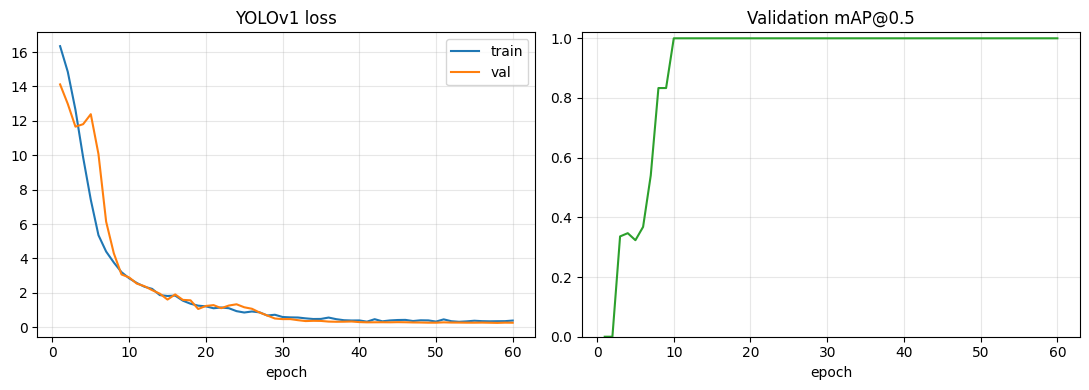


 YOLOv1 - DJI Phantom : TEST RESULTS
 mAP@0.5            : 1.0000
 mAP@0.5:0.95       : 0.9667
   AP@0.5 [sunny  ] : 1.0000   P=1.000 R=1.000 F1=1.000
   AP@0.5 [evening] : 1.0000   P=1.000 R=1.000 F1=1.000
   AP@0.5 [cloudy ] : 1.0000   P=1.000 R=1.000 F1=1.000
 Precision / Recall / F1 (macro, conf>=0.25): 1.000 / 1.000 / 1.000
 Classification accuracy (localised drones) : 1.0000
 Image-level scenario accuracy              : 1.0000
 Detection accuracy TP/(TP+FP+FN)           : 1.0000
 Confusion matrix (rows=GT, cols=pred, last=background):
                  sunny    evening     cloudy background
       sunny          6          0          0          0
     evening          0          6          0          0
      cloudy          0          0          6          0
   background          0          0          0          0
 EFFICIENCY  (cuda (Tesla T4))
 Parameters         : 20,623,437 (20.62 M)
 Model size (fp32)  : 78.7 MB   | checkpoint file: 78.8 MB
 Compute            : 15.4 GFLOPs

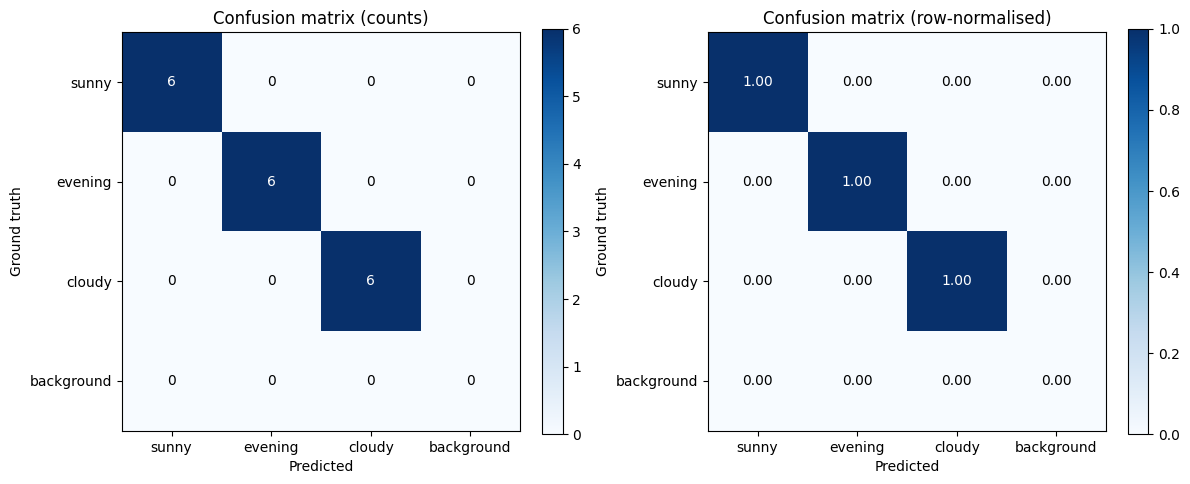

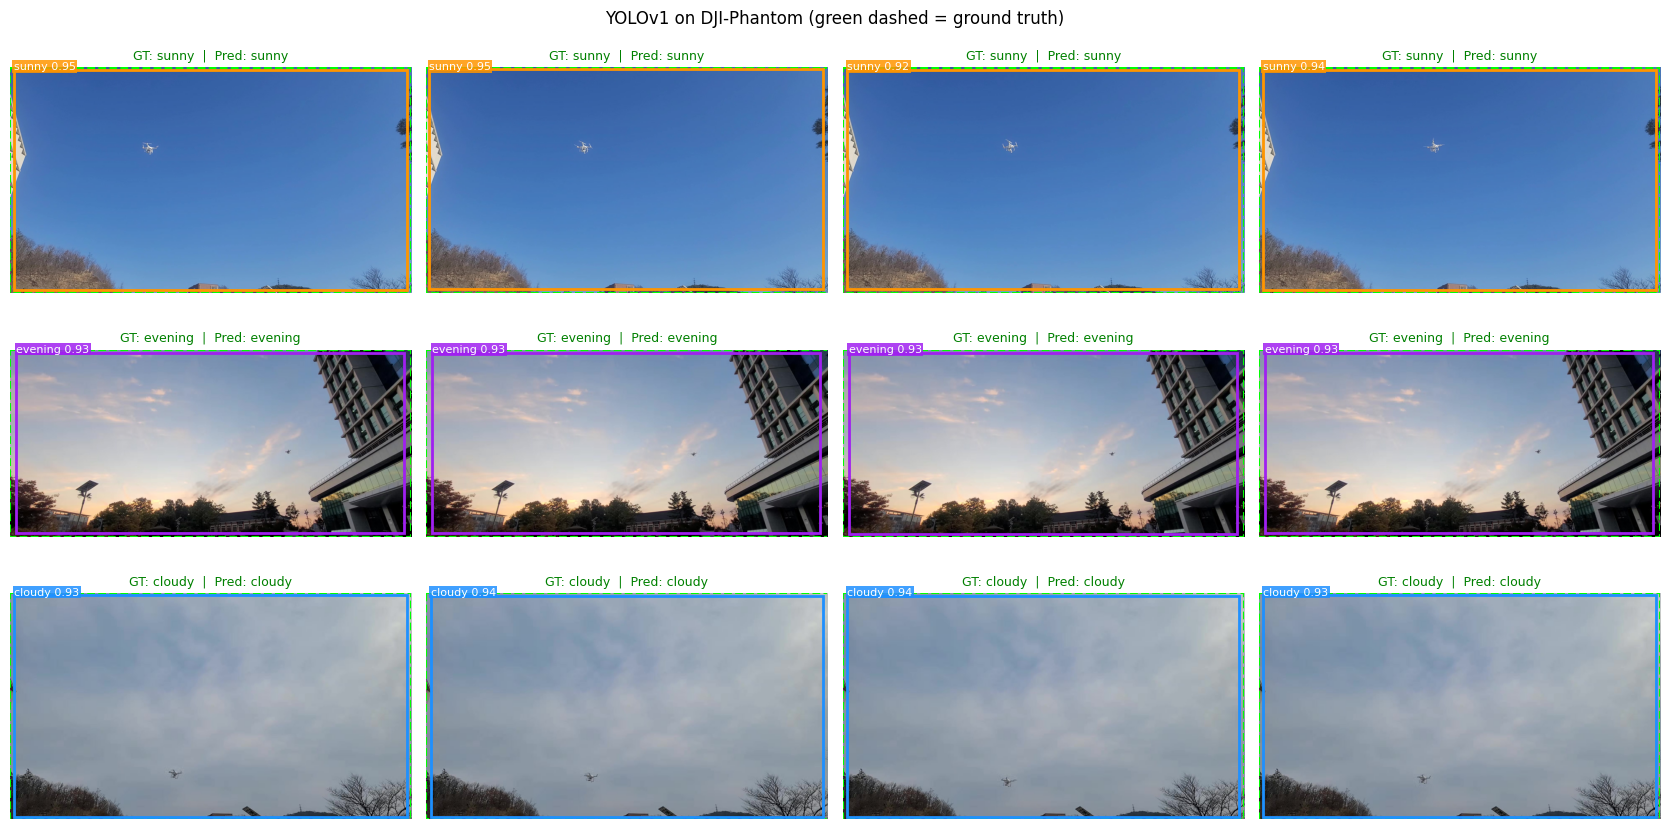

[done] results saved in: /content/drive/MyDrive/YOLOv1_DJI_Phantom_Corrected


In [30]:
import sys

ARCH   = "resnet18"
EPOCHS = 60
BATCH  = 16
FC_DIM = 4096

# Aligning the output directory with where your drive structures are currently located
OUT_DIR = "/content/drive/MyDrive/YOLOv1_DJI_Phantom_Corrected"

sys.argv = ["yolov1", "train",
            "--images_dir", IMAGES_DIR, "--labels_dir", LABELS_DIR, "--out_dir", OUT_DIR,
            "--arch", ARCH, "--fc_dim", str(FC_DIM),
            "--epochs", str(EPOCHS), "--batch", str(BATCH),
            "--amp", "--workers", "2", "--show"]
main()

In [ ]:
script 2
EPOCHS = 100
BATCH  = 64

[info] device: cuda
[data] 104 labelled images found (0 skipped: no label/box).
[data] train:    71 images  sunny=23  evening=23  cloudy=25
[data] val  :    15 images  sunny=5  evening=5  cloudy=5
[data] test :    18 images  sunny=6  evening=6  cloudy=6
[model] resnet18: 20.6 M parameters


/tmp/ipykernel_442/550367123.py:56: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()  # <-- FIXED: Call scheduler step directly after optimizer step


[ep   1/100] train 16.335 | val 14.282 | val mAP@0.5 0.000 | 5s
[ep   2/100] train 16.488 | val 14.256 | val mAP@0.5 0.000 | 7s
[ep   3/100] train 16.394 | val 14.263 | val mAP@0.5 0.000 | 5s
[ep   4/100] train 16.363 | val 13.445 | val mAP@0.5 0.000 | 9s
[ep   5/100] train 14.689 | val 13.615 | val mAP@0.5 0.083 | 6s
[ep   6/100] train 13.683 | val 13.218 | val mAP@0.5 0.267 | 7s
[ep   7/100] train 12.604 | val 12.416 | val mAP@0.5 0.300 | 6s
[ep   8/100] train 11.342 | val 12.190 | val mAP@0.5 0.300 | 8s
[ep   9/100] train 10.300 | val 13.085 | val mAP@0.5 0.315 | 6s
[ep  10/100] train 9.115 | val 13.898 | val mAP@0.5 0.345 | 7s
[ep  11/100] train 7.856 | val 14.690 | val mAP@0.5 0.351 | 5s
[ep  12/100] train 7.109 | val 14.162 | val mAP@0.5 0.246 | 6s
[ep  13/100] train 6.241 | val 15.144 | val mAP@0.5 0.176 | 8s
[ep  14/100] train 5.479 | val 14.713 | val mAP@0.5 0.153 | 6s
[ep  15/100] train 5.104 | val 13.209 | val mAP@0.5 0.159 | 6s
[ep  16/100] train 4.729 | val 12.263 | val mA

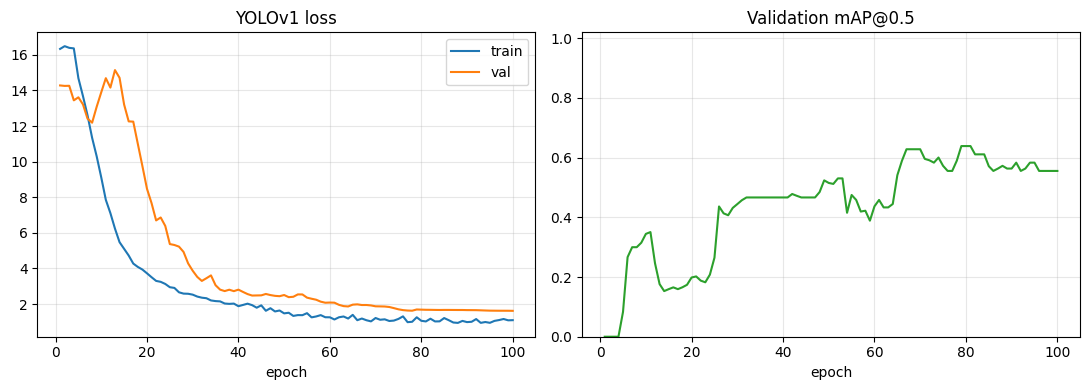


 YOLOv1 - DJI Phantom : TEST RESULTS
 mAP@0.5            : 0.6333
 mAP@0.5:0.95       : 0.3912
   AP@0.5 [sunny  ] : 1.0000   P=0.000 R=0.000 F1=0.000
   AP@0.5 [evening] : 0.4000   P=1.000 R=1.000 F1=1.000
   AP@0.5 [cloudy ] : 0.5000   P=0.500 R=1.000 F1=0.667
 Precision / Recall / F1 (macro, conf>=0.25): 0.500 / 0.667 / 0.556
 Classification accuracy (localised drones) : 0.6667
 Image-level scenario accuracy              : 0.6667
 Detection accuracy TP/(TP+FP+FN)           : 0.5000
 Confusion matrix (rows=GT, cols=pred, last=background):
                  sunny    evening     cloudy background
       sunny          0          0          6          0
     evening          0          6          0          0
      cloudy          0          0          6          0
   background          0          0          0          0
 EFFICIENCY  (cuda (Tesla T4))
 Parameters         : 20,623,437 (20.62 M)
 Model size (fp32)  : 78.7 MB   | checkpoint file: 78.8 MB
 Compute            : 15.4 GFLOPs

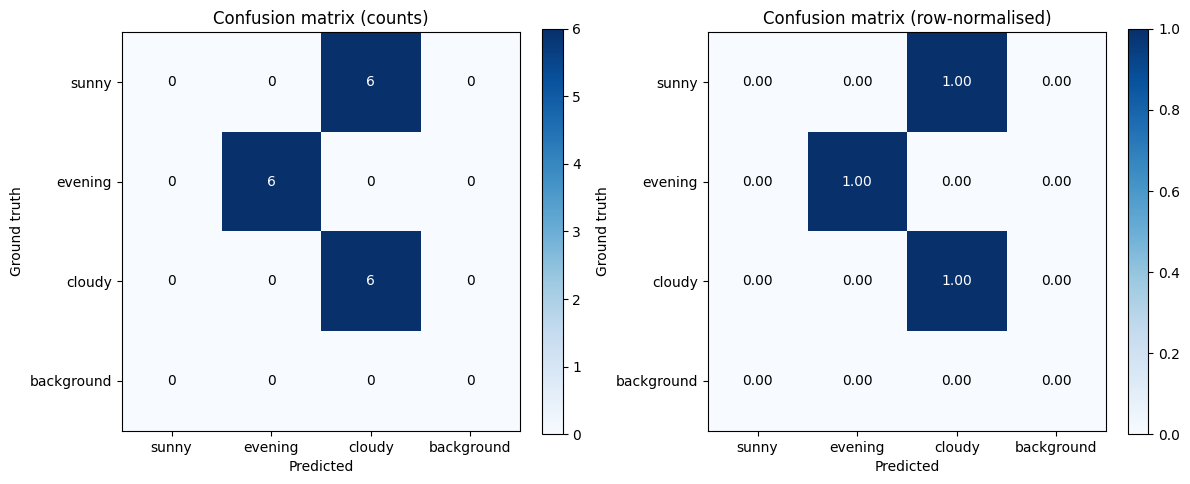

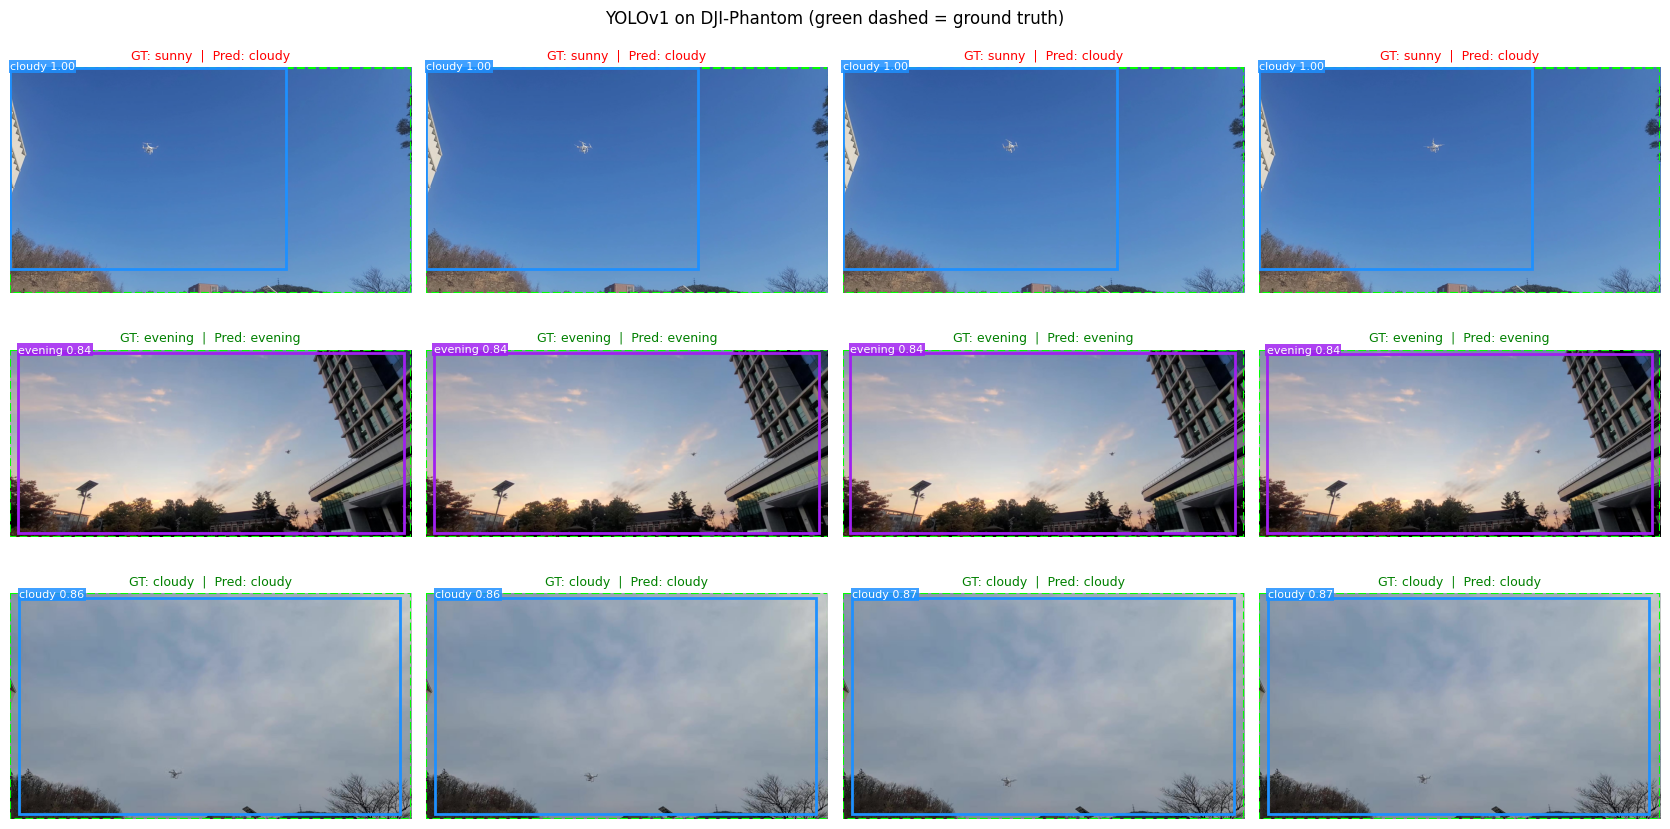

[done] results saved in: /content/drive/MyDrive/YOLOv1_DJI_Phantom_Corrected


In [31]:
import sys

ARCH   = "resnet18"
EPOCHS = 100
BATCH  = 64
FC_DIM = 4096

# Aligning the output directory with where your drive structures are currently located
OUT_DIR = "/content/drive/MyDrive/YOLOv1_DJI_Phantom_Corrected"

sys.argv = ["yolov1", "train",
            "--images_dir", IMAGES_DIR, "--labels_dir", LABELS_DIR, "--out_dir", OUT_DIR,
            "--arch", ARCH, "--fc_dim", str(FC_DIM),
            "--epochs", str(EPOCHS), "--batch", str(BATCH),
            "--amp", "--workers", "2", "--show"]
main()

In [ ]:
sript 3
EPOCHS = 100
BATCH  = 32

[info] device: cuda
[data] 104 labelled images found (0 skipped: no label/box).
[data] train:    71 images  sunny=23  evening=23  cloudy=25
[data] val  :    15 images  sunny=5  evening=5  cloudy=5
[data] test :    18 images  sunny=6  evening=6  cloudy=6
[model] resnet18: 20.6 M parameters


/tmp/ipykernel_442/550367123.py:56: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()  # <-- FIXED: Call scheduler step directly after optimizer step


[ep   1/100] train 16.412 | val 14.259 | val mAP@0.5 0.000 | 5s
[ep   2/100] train 16.357 | val 13.311 | val mAP@0.5 0.000 | 6s
[ep   3/100] train 14.479 | val 12.715 | val mAP@0.5 0.253 | 5s
[ep   4/100] train 12.587 | val 11.647 | val mAP@0.5 0.333 | 7s
[ep   5/100] train 10.765 | val 11.877 | val mAP@0.5 0.362 | 5s
[ep   6/100] train 8.291 | val 12.729 | val mAP@0.5 0.396 | 4s
[ep   7/100] train 6.703 | val 12.202 | val mAP@0.5 0.403 | 7s
[ep   8/100] train 5.592 | val 10.562 | val mAP@0.5 0.437 | 5s
[ep   9/100] train 4.740 | val 8.838 | val mAP@0.5 0.472 | 6s
[ep  10/100] train 4.371 | val 6.781 | val mAP@0.5 0.565 | 5s
[ep  11/100] train 3.941 | val 5.486 | val mAP@0.5 0.568 | 5s
[ep  12/100] train 3.626 | val 4.497 | val mAP@0.5 0.604 | 7s
[ep  13/100] train 3.372 | val 3.676 | val mAP@0.5 0.652 | 5s
[ep  14/100] train 3.106 | val 3.223 | val mAP@0.5 0.810 | 6s
[ep  15/100] train 2.993 | val 2.813 | val mAP@0.5 0.780 | 5s
[ep  16/100] train 2.879 | val 2.814 | val mAP@0.5 0.685 

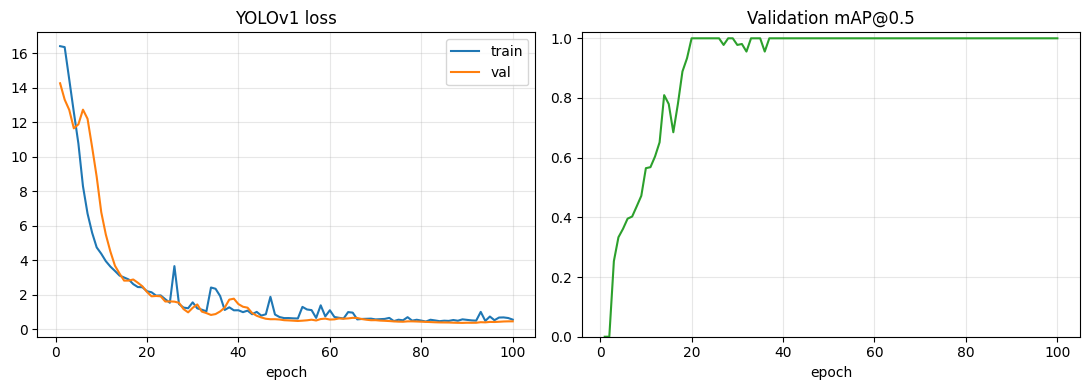


 YOLOv1 - DJI Phantom : TEST RESULTS
 mAP@0.5            : 1.0000
 mAP@0.5:0.95       : 0.8611
   AP@0.5 [sunny  ] : 1.0000   P=1.000 R=1.000 F1=1.000
   AP@0.5 [evening] : 1.0000   P=1.000 R=1.000 F1=1.000
   AP@0.5 [cloudy ] : 1.0000   P=1.000 R=1.000 F1=1.000
 Precision / Recall / F1 (macro, conf>=0.25): 1.000 / 1.000 / 1.000
 Classification accuracy (localised drones) : 1.0000
 Image-level scenario accuracy              : 1.0000
 Detection accuracy TP/(TP+FP+FN)           : 1.0000
 Confusion matrix (rows=GT, cols=pred, last=background):
                  sunny    evening     cloudy background
       sunny          6          0          0          0
     evening          0          6          0          0
      cloudy          0          0          6          0
   background          0          0          0          0
 EFFICIENCY  (cuda (Tesla T4))
 Parameters         : 20,623,437 (20.62 M)
 Model size (fp32)  : 78.7 MB   | checkpoint file: 78.8 MB
 Compute            : 15.4 GFLOPs

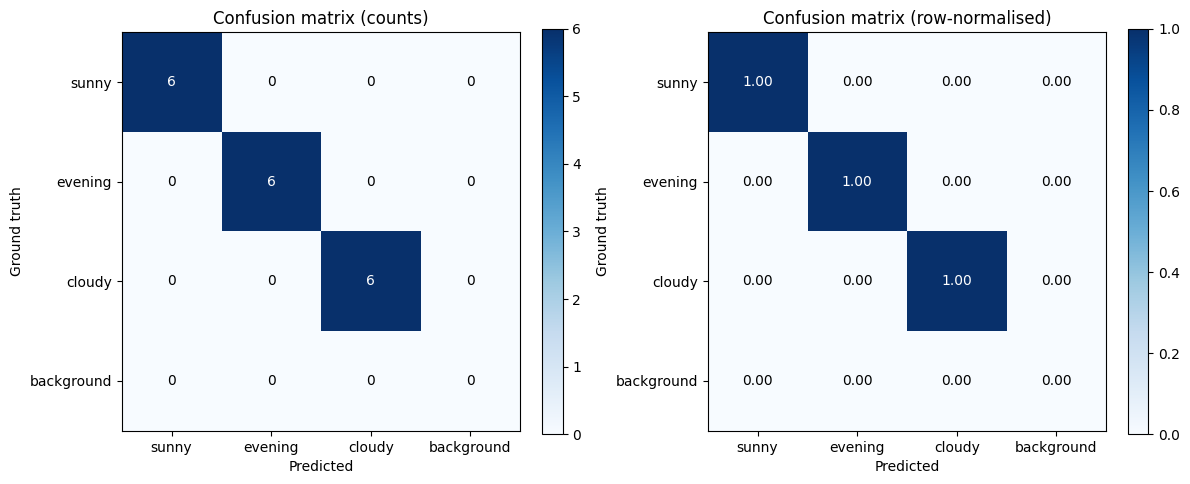

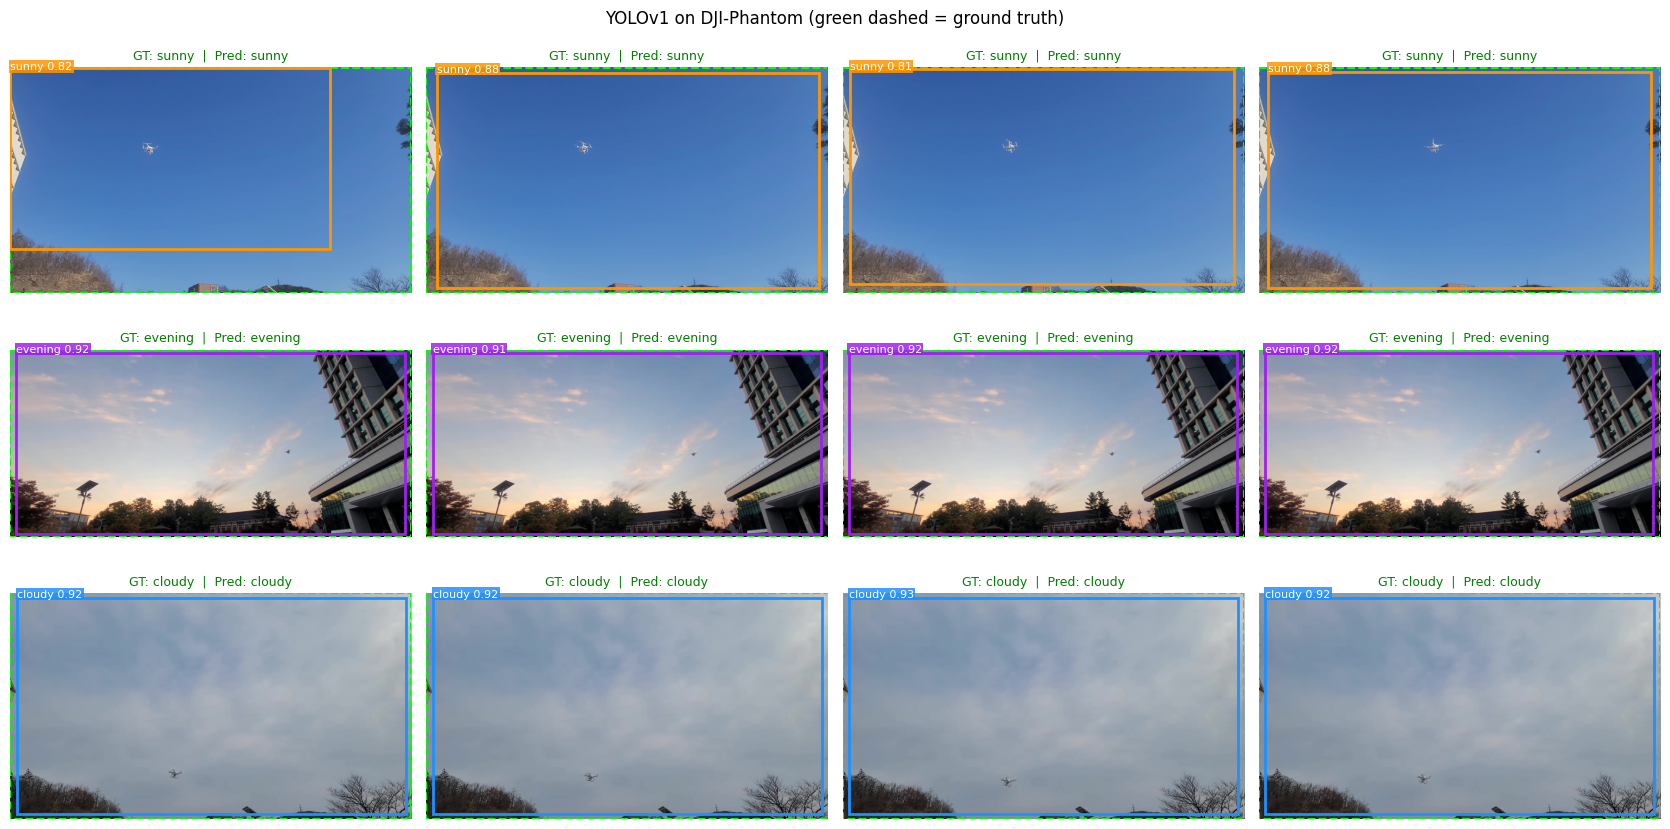

[done] results saved in: /content/drive/MyDrive/YOLOv1_DJI_Phantom_Corrected


In [32]:
import sys

ARCH   = "resnet18"
EPOCHS = 100
BATCH  = 32
FC_DIM = 4096

# Aligning the output directory with where your drive structures are currently located
OUT_DIR = "/content/drive/MyDrive/YOLOv1_DJI_Phantom_Corrected"

sys.argv = ["yolov1", "train",
            "--images_dir", IMAGES_DIR, "--labels_dir", LABELS_DIR, "--out_dir", OUT_DIR,
            "--arch", ARCH, "--fc_dim", str(FC_DIM),
            "--epochs", str(EPOCHS), "--batch", str(BATCH),
            "--amp", "--workers", "2", "--show"]
main()

**script 4 **
EPOCHS = 100
BATCH  = 8

[info] device: cuda
[data] 104 labelled images found (0 skipped: no label/box).
[data] train:    71 images  sunny=23  evening=23  cloudy=25
[data] val  :    15 images  sunny=5  evening=5  cloudy=5
[data] test :    18 images  sunny=6  evening=6  cloudy=6
[model] resnet18: 20.6 M parameters


/tmp/ipykernel_442/550367123.py:56: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()  # <-- FIXED: Call scheduler step directly after optimizer step


[ep   1/100] train 16.017 | val 13.534 | val mAP@0.5 0.000 | 5s
[ep   2/100] train 13.704 | val 11.900 | val mAP@0.5 0.533 | 6s
[ep   3/100] train 10.769 | val 9.234 | val mAP@0.5 0.388 | 5s
[ep   4/100] train 6.975 | val 7.790 | val mAP@0.5 0.384 | 7s
[ep   5/100] train 4.815 | val 5.885 | val mAP@0.5 0.391 | 6s
[ep   6/100] train 3.320 | val 3.164 | val mAP@0.5 0.519 | 4s
[ep   7/100] train 2.594 | val 2.078 | val mAP@0.5 1.000 | 7s
[ep   8/100] train 1.871 | val 1.808 | val mAP@0.5 0.970 | 4s
[ep   9/100] train 1.542 | val 1.277 | val mAP@0.5 1.000 | 5s
[ep  10/100] train 1.223 | val 1.026 | val mAP@0.5 1.000 | 6s
[ep  11/100] train 0.964 | val 0.797 | val mAP@0.5 1.000 | 5s
[ep  12/100] train 0.865 | val 0.607 | val mAP@0.5 1.000 | 7s
[ep  13/100] train 0.722 | val 0.527 | val mAP@0.5 1.000 | 5s
[ep  14/100] train 0.622 | val 0.386 | val mAP@0.5 1.000 | 5s
[ep  15/100] train 0.482 | val 0.322 | val mAP@0.5 1.000 | 6s
[ep  16/100] train 0.444 | val 0.338 | val mAP@0.5 1.000 | 5s
[ep

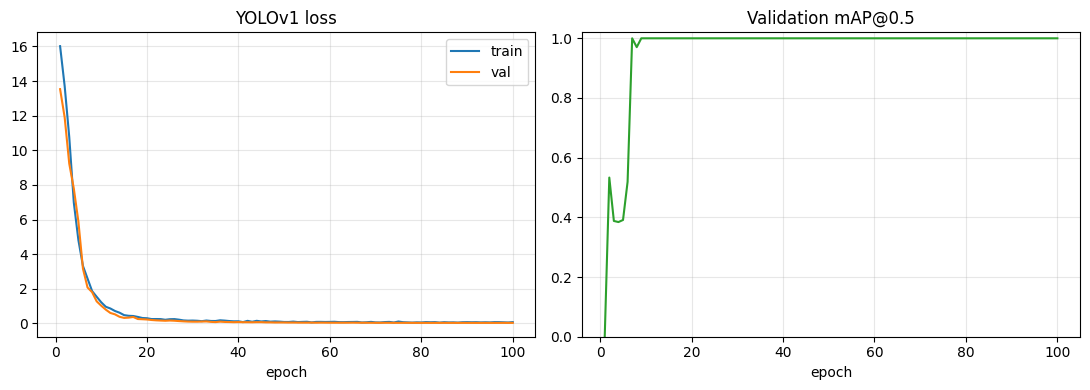


 YOLOv1 - DJI Phantom : TEST RESULTS
 mAP@0.5            : 1.0000
 mAP@0.5:0.95       : 1.0000
   AP@0.5 [sunny  ] : 1.0000   P=1.000 R=1.000 F1=1.000
   AP@0.5 [evening] : 1.0000   P=1.000 R=1.000 F1=1.000
   AP@0.5 [cloudy ] : 1.0000   P=1.000 R=1.000 F1=1.000
 Precision / Recall / F1 (macro, conf>=0.25): 1.000 / 1.000 / 1.000
 Classification accuracy (localised drones) : 1.0000
 Image-level scenario accuracy              : 1.0000
 Detection accuracy TP/(TP+FP+FN)           : 1.0000
 Confusion matrix (rows=GT, cols=pred, last=background):
                  sunny    evening     cloudy background
       sunny          6          0          0          0
     evening          0          6          0          0
      cloudy          0          0          6          0
   background          0          0          0          0
 EFFICIENCY  (cuda (Tesla T4))
 Parameters         : 20,623,437 (20.62 M)
 Model size (fp32)  : 78.7 MB   | checkpoint file: 78.8 MB
 Compute            : 15.4 GFLOPs

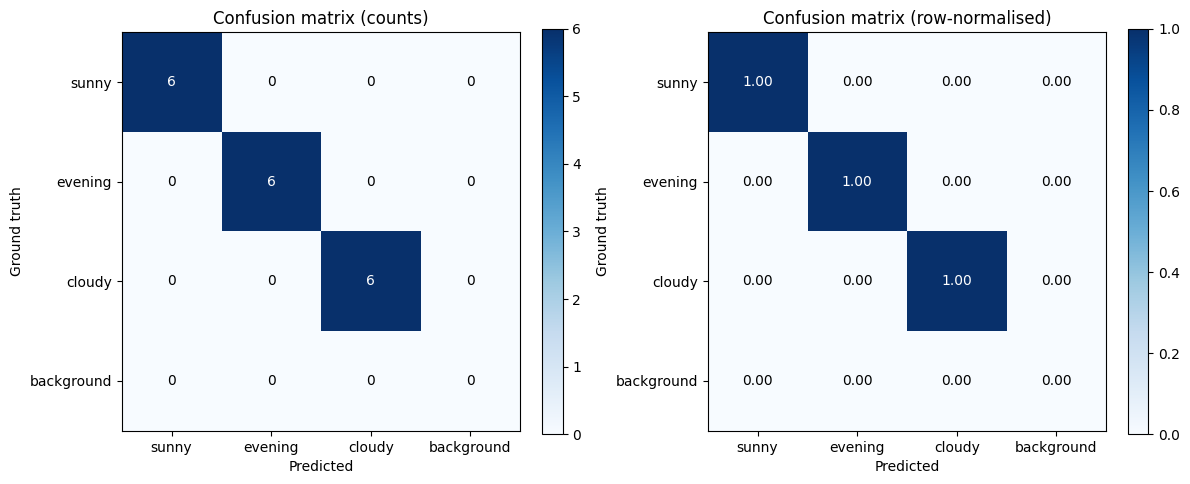

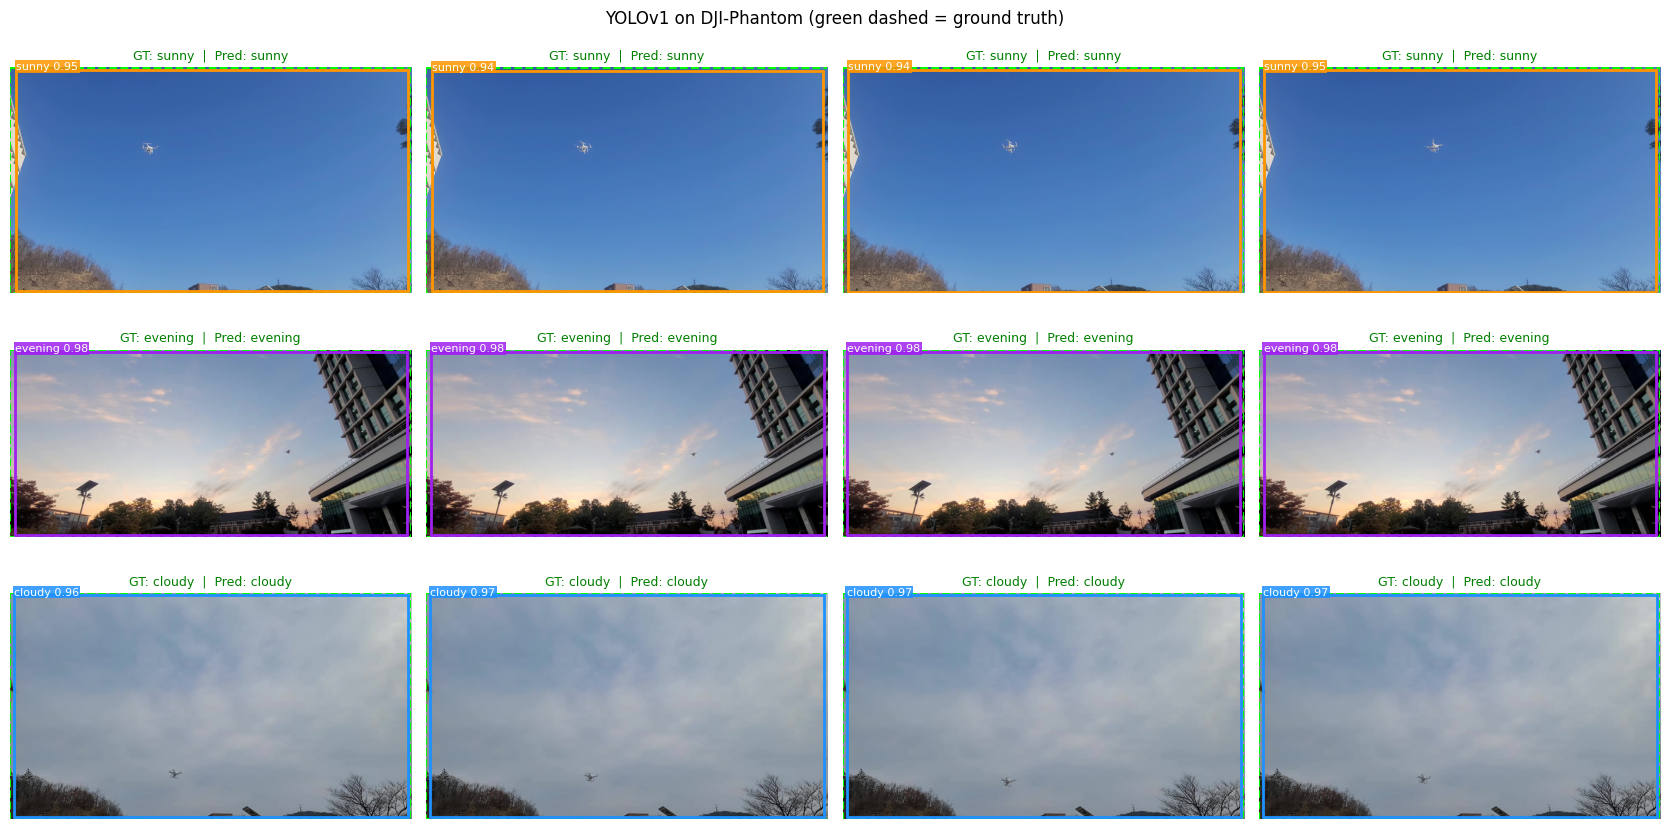

[done] results saved in: /content/drive/MyDrive/YOLOv1_DJI_Phantom_Corrected


In [33]:
import sys

ARCH   = "resnet18"
EPOCHS = 100
BATCH  = 8
FC_DIM = 4096

# Aligning the output directory with where your drive structures are currently located
OUT_DIR = "/content/drive/MyDrive/YOLOv1_DJI_Phantom_Corrected"

sys.argv = ["yolov1", "train",
            "--images_dir", IMAGES_DIR, "--labels_dir", LABELS_DIR, "--out_dir", OUT_DIR,
            "--arch", ARCH, "--fc_dim", str(FC_DIM),
            "--epochs", str(EPOCHS), "--batch", str(BATCH),
            "--amp", "--workers", "2", "--show"]
main()

In [ ]:
script 4\8

[info] device: cuda
[data] 104 labelled images found (0 skipped: no label/box).
[data] train:    71 images  sunny=23  evening=23  cloudy=25
[data] val  :    15 images  sunny=5  evening=5  cloudy=5
[data] test :    18 images  sunny=6  evening=6  cloudy=6
[model] resnet18: 20.6 M parameters


/tmp/ipykernel_442/550367123.py:56: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()  # <-- FIXED: Call scheduler step directly after optimizer step


[ep   1/100] train 16.017 | val 13.534 | val mAP@0.5 0.000 | 5s
[ep   2/100] train 13.704 | val 11.900 | val mAP@0.5 0.533 | 4s
[ep   3/100] train 10.769 | val 9.234 | val mAP@0.5 0.388 | 7s
[ep   4/100] train 6.975 | val 7.790 | val mAP@0.5 0.384 | 7s
[ep   5/100] train 4.815 | val 5.885 | val mAP@0.5 0.391 | 7s
[ep   6/100] train 3.320 | val 3.164 | val mAP@0.5 0.519 | 4s
[ep   7/100] train 2.594 | val 2.078 | val mAP@0.5 1.000 | 4s
[ep   8/100] train 1.871 | val 1.808 | val mAP@0.5 0.970 | 7s
[ep   9/100] train 1.542 | val 1.277 | val mAP@0.5 1.000 | 5s
[ep  10/100] train 1.223 | val 1.026 | val mAP@0.5 1.000 | 5s
[ep  11/100] train 0.964 | val 0.797 | val mAP@0.5 1.000 | 6s
[ep  12/100] train 0.865 | val 0.607 | val mAP@0.5 1.000 | 5s
[ep  13/100] train 0.722 | val 0.527 | val mAP@0.5 1.000 | 7s
[ep  14/100] train 0.622 | val 0.386 | val mAP@0.5 1.000 | 5s
[ep  15/100] train 0.482 | val 0.322 | val mAP@0.5 1.000 | 4s
[ep  16/100] train 0.444 | val 0.338 | val mAP@0.5 1.000 | 7s
[ep

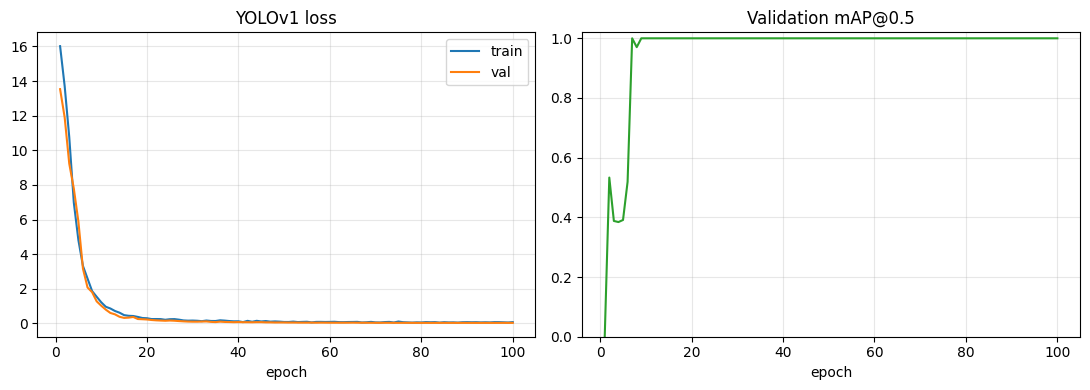


 YOLOv1 - DJI Phantom : TEST RESULTS
 mAP@0.5            : 1.0000
 mAP@0.5:0.95       : 1.0000
   AP@0.5 [sunny  ] : 1.0000   P=1.000 R=1.000 F1=1.000
   AP@0.5 [evening] : 1.0000   P=1.000 R=1.000 F1=1.000
   AP@0.5 [cloudy ] : 1.0000   P=1.000 R=1.000 F1=1.000
 Precision / Recall / F1 (macro, conf>=0.25): 1.000 / 1.000 / 1.000
 Classification accuracy (localised drones) : 1.0000
 Image-level scenario accuracy              : 1.0000
 Detection accuracy TP/(TP+FP+FN)           : 1.0000
 Confusion matrix (rows=GT, cols=pred, last=background):
                  sunny    evening     cloudy background
       sunny          6          0          0          0
     evening          0          6          0          0
      cloudy          0          0          6          0
   background          0          0          0          0
 EFFICIENCY  (cuda (Tesla T4))
 Parameters         : 20,623,437 (20.62 M)
 Model size (fp32)  : 78.7 MB   | checkpoint file: 78.8 MB
 Compute            : 15.4 GFLOPs

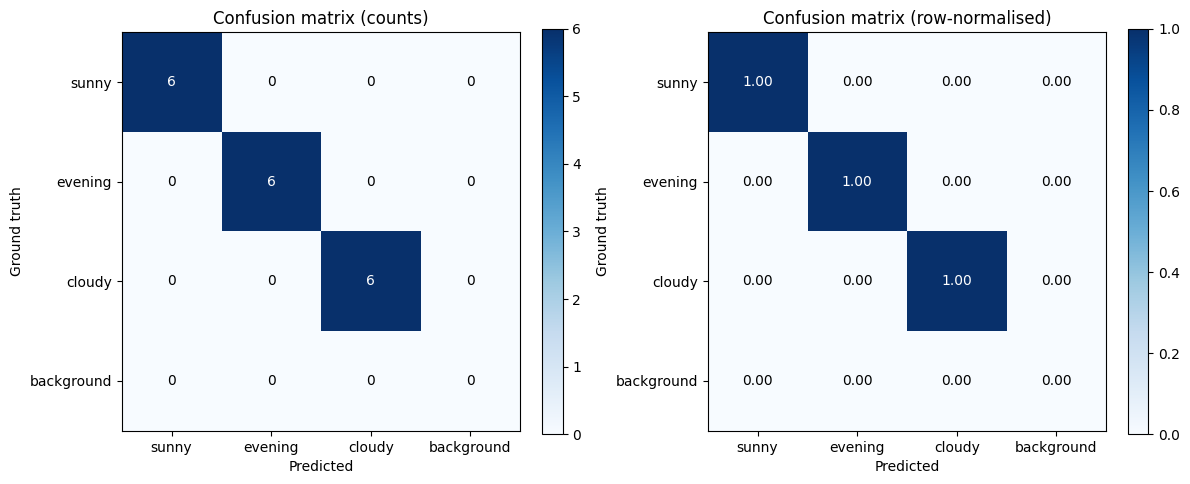

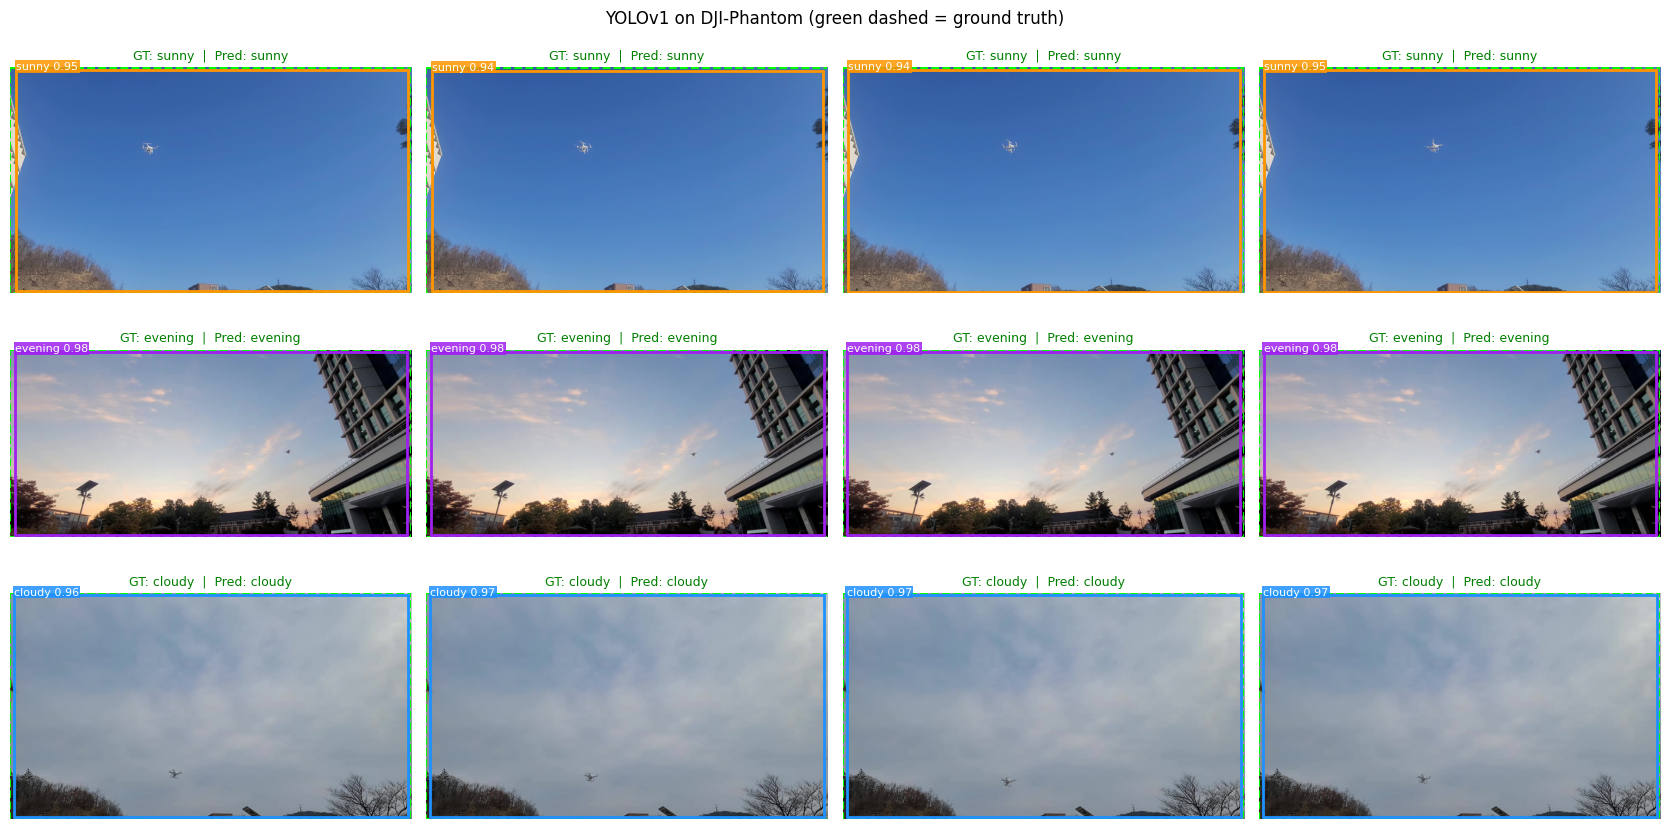

[done] results saved in: /content/drive/MyDrive/YOLOv1_DJI_Phantom_Corrected


In [34]:
import sys

ARCH   = "resnet18"
EPOCHS = 100
BATCH  = 8
FC_DIM = 4096

# Aligning the output directory with where your drive structures are currently located
OUT_DIR = "/content/drive/MyDrive/YOLOv1_DJI_Phantom_Corrected"

sys.argv = ["yolov1", "train",
            "--images_dir", IMAGES_DIR, "--labels_dir", LABELS_DIR, "--out_dir", OUT_DIR,
            "--arch", ARCH, "--fc_dim", str(FC_DIM),
            "--epochs", str(EPOCHS), "--batch", str(BATCH),
            "--amp", "--workers", "2", "--show"]
main()

In [28]:
import matplotlib.pyplot as plt
import matplotlib.patches as mp
import numpy as np
from PIL import Image
import random

def plot_training(history, path, show):
    ep = [h["epoch"] for h in history]
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(ep, [h["train_loss"] for h in history], label="train")
    ax[0].plot(ep, [h["val_loss"] for h in history], label="val")
    ax[0].set(title="YOLOv1 loss", xlabel="epoch"), ax[0].legend(), ax[0].grid(alpha=.3)
    ax[1].plot(ep, [h["val_mAP50"] for h in history], color="tab:green")
    ax[1].set(title="Validation mAP@0.5", xlabel="epoch", ylim=(0, 1.02)), ax[1].grid(alpha=.3)
    fig.tight_layout(), fig.savefig(path, dpi=150)
    if show:
        plt.show()
    plt.close(fig)

def plot_confusion(cm, path, show):
    cm = np.array(cm)
    labels = CLASSES + ["background"]
    norm = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    for a, m, t, fmt in ((ax[0], cm, "Confusion matrix (counts)", "d"),
                         (ax[1], norm, "Confusion matrix (row-normalised)", ".2f")):
        im = a.imshow(m, cmap="Blues")
        a.set(xticks=range(C + 1), yticks=range(C + 1), xticklabels=labels, yticklabels=labels,
              xlabel="Predicted", ylabel="Ground truth", title=t)
        for i in range(C + 1):
            for j in range(C + 1):
                a.text(j, i, format(m[i, j], fmt), ha="center", va="center",
                       color="white" if m[i, j] > m.max() / 2 else "black")
        fig.colorbar(im, ax=a, fraction=.046)
    fig.tight_layout(), fig.savefig(path, dpi=150)
    if show:
        plt.show()
    plt.close(fig)

def visualize(samples, preds, gts, path, n, show, seed=0):
    rng = random.Random(seed)
    per = max(1, n // C)
    idx = []
    for c in range(C):
        ids = [i for i, s in enumerate(samples) if s["cls"] == c]
        rng.shuffle(ids)
        idx += ids[:per]
    cols = per
    fig, axes = plt.subplots(C, cols, figsize=(4.2 * cols, 2.9 * C), squeeze=False)
    for a in axes.ravel():
        a.axis("off")
    for k, i in enumerate(idx):
        a = axes[k // cols][k % cols]
        img = Image.open(samples[i]["image"]).convert("RGB")
        W, H = img.size
        a.imshow(img)
        for g in gts[i]:
            x1, y1, x2, y2 = g[1] * W, g[2] * H, g[3] * W, g[4] * H
            a.add_patch(mp.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="lime", ls="--", lw=1.5))
        p = preds[i]
        for d in p[:5]:
            x1, y1, x2, y2 = d[0] * W, d[1] * H, d[2] * W, d[3] * H
            name = CLASSES[int(d[5])]
            a.add_patch(mp.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False,
                                     ec=CLASS_COLORS[name], lw=2))
            a.text(x1, max(y1 - 4, 8), f"{name} {d[4]:.2f}", color="white", fontsize=8,
                   bbox=dict(facecolor=CLASS_COLORS[name], alpha=.85, pad=1, lw=0))
        gt_name = CLASSES[samples[i]["cls"]]
        top = CLASSES[int(p[p[:, 4].argmax(), 5])] if len(p) else "no detection"
        a.set_title(f"GT: {gt_name}  |  Pred: {top}", fontsize=9,
                    color="green" if top == gt_name else "red")
        a.axis("off")
    fig.suptitle("YOLOv1 on DJI-Phantom (green dashed = ground truth)", fontsize=12)
    fig.tight_layout(), fig.savefig(path, dpi=150)
    if show:
        plt.show()
    plt.close(fig)

def print_report(m, eff):
    line = "=" * 68
    print(f"\n{line}\n YOLOv1 - DJI Phantom : TEST RESULTS\n{line}")
    print(f" mAP@0.5            : {m["mAP@0.5"]:.4f}")
    print(f" mAP@0.5:0.95       : {m["mAP@0.5:0.95"]:.4f}")
    for c in CLASSES:
        print(f"   AP@0.5 [{c:7s}] : {m["AP@0.5_per_class"][c]:.4f}   "
              f"P={m["per_class"][c]["precision"]:.3f} R={m["per_class"][c]["recall"]:.3f} "
              f"F1={m["per_class"][c]["f1"]:.3f}")
    print(f" Precision / Recall / F1 (macro, conf>={m["conf_threshold"]}): "
          f"{m["precision_macro"]:.3f} / {m["recall_macro"]:.3f} / {m["f1_macro"]:.3f}")
    print(f" Classification accuracy (localised drones) : {m["classification_accuracy_on_localized_drones"]:.4f}")
    print(f" Image-level scenario accuracy              : {m["image_level_scenario_accuracy"]:.4f}")
    print(f" Detection accuracy TP/(TP+FP+FN)           : {m["detection_accuracy_TP/(TP+FP+FN)"]:.4f}")
    print(" Confusion matrix (rows=GT, cols=pred, last=background):")
    print("            " + "".join(f"{l:>11s}" for l in m["confusion_matrix_labels"]))
    for l, row in zip(m["confusion_matrix_labels"], m["confusion_matrix"]):
        print(f"   {l:>9s}" + "".join(f"{v:11d}" for v in row))
    print(f"{line}\n EFFICIENCY  ({eff["device"]})\n{line}")
    print(f" Parameters         : {eff["parameters"]:,} ({eff["parameters_M"]:.2f} M)")
    print(f" Model size (fp32)  : {eff["model_size_MB_fp32"]:.1f} MB"
          + (f"   | checkpoint file: {eff["checkpoint_file_MB"]:.1f} MB" if "checkpoint_file_MB" in eff else ""))
    if eff["GFLOPs"]:
        print(f" Compute            : {eff["GFLOPs"]:.1f} GFLOPs / image")
    print(f" Latency (model)    : {eff["latency_model_ms_mean"]:.2f} +/- {eff["latency_model_ms_std"]:.2f} ms "
          f"(p95 {eff["latency_model_ms_p95"]:.2f} ms)")
    print(f" FPS (model, bs=1)  : {eff["FPS_model_only_bs1"]:.1f}")
    print(f" Latency end-to-end : {eff["latency_end_to_end_ms_mean"]:.2f} ms  -> {eff["FPS_end_to_end_bs1"]:.1f} FPS")
    k = [k for k in eff if k.startswith("throughput")][0]
    print(f" {k:19s}: {eff[k]:.1f}\n{line}\n")

print("Helper functions registered successfully!")

Helper functions registered successfully!


## 6. (Optional) Re-evaluate a saved checkpoint later
Use this after a disconnect - no retraining needed. Run sections 1-4 first.

[info] device: cuda
[data] 104 labelled images found (0 skipped: no label/box).
[data] train:    71 images  sunny=23  evening=23  cloudy=25
[data] val  :    15 images  sunny=5  evening=5  cloudy=5
[data] test :    18 images  sunny=6  evening=6  cloudy=6

 YOLOv1 - DJI Phantom : TEST RESULTS
 mAP@0.5            : 1.0000
 mAP@0.5:0.95       : 0.9667
   AP@0.5 [sunny  ] : 1.0000   P=1.000 R=1.000 F1=1.000
   AP@0.5 [evening] : 1.0000   P=1.000 R=1.000 F1=1.000
   AP@0.5 [cloudy ] : 1.0000   P=1.000 R=1.000 F1=1.000
 Precision / Recall / F1 (macro, conf>=0.25): 1.000 / 1.000 / 1.000
 Classification accuracy (localised drones) : 1.0000
 Image-level scenario accuracy              : 1.0000
 Detection accuracy TP/(TP+FP+FN)           : 1.0000
 Confusion matrix (rows=GT, cols=pred, last=background):
                  sunny    evening     cloudy background
       sunny          6          0          0          0
     evening          0          6          0          0
      cloudy          0    

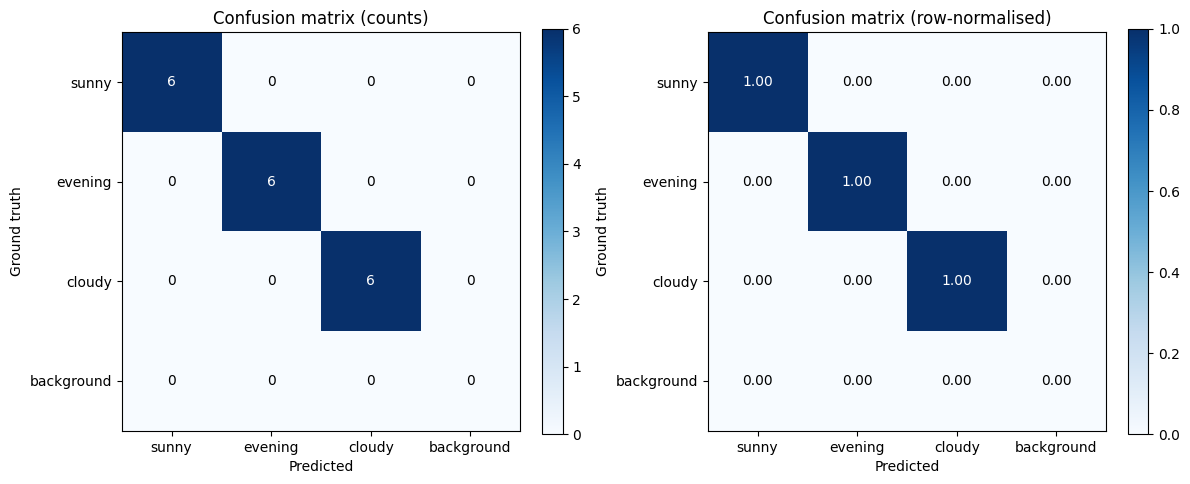

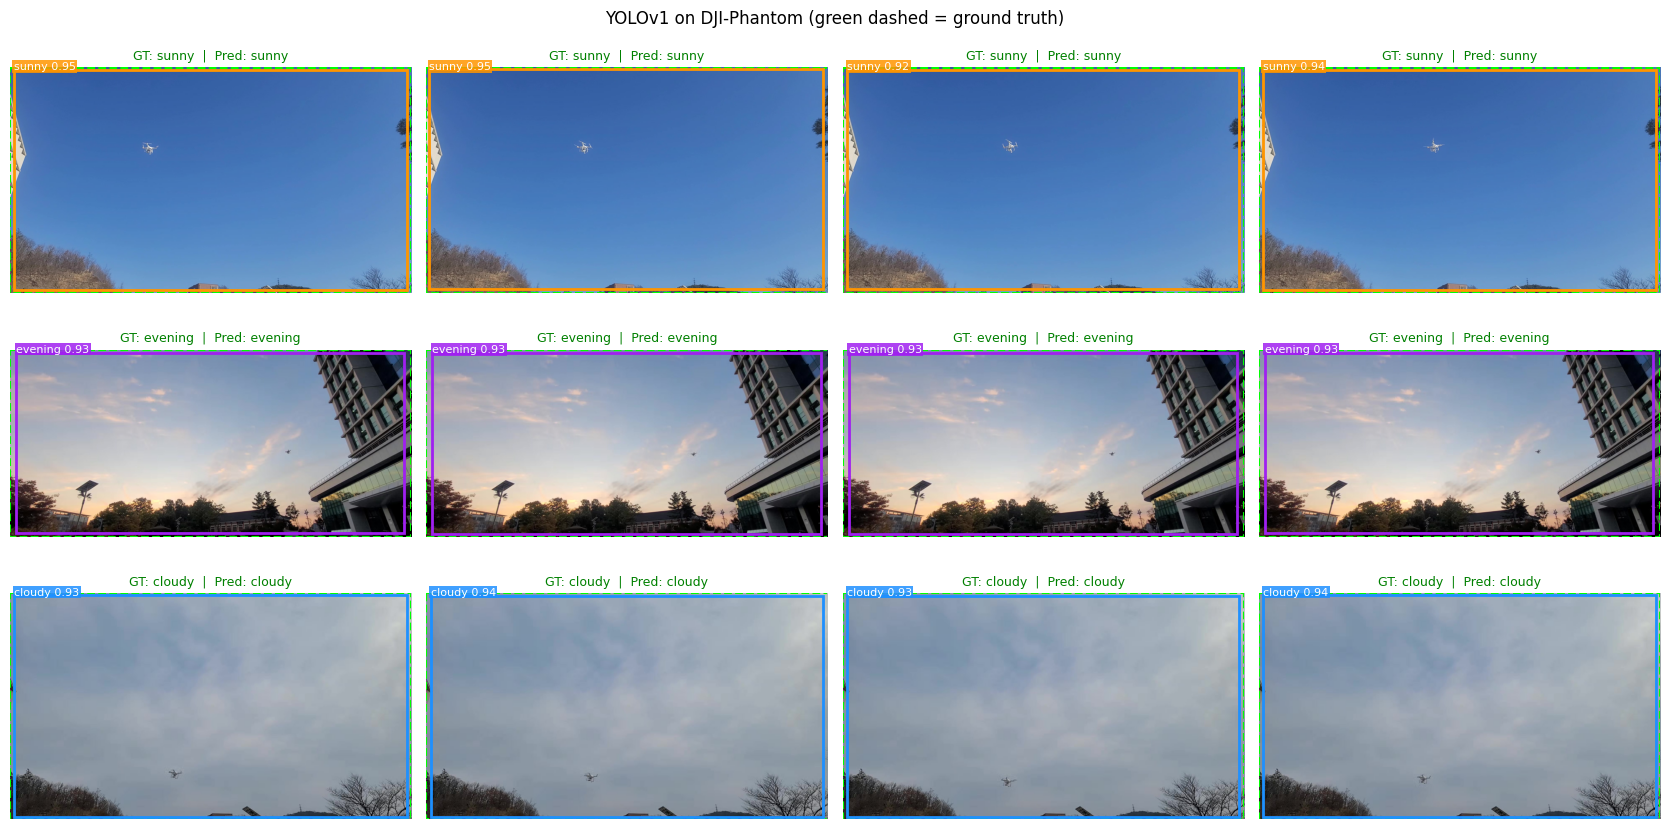

[done] results saved in: /content/drive/MyDrive/YOLOv1_DJI_Phantom_Corrected


In [29]:
import sys

sys.argv = ["yolov1", "eval",
            "--images_dir", IMAGES_DIR, "--labels_dir", LABELS_DIR, "--out_dir", OUT_DIR,
            "--weights", OUT_DIR + "/best.pt", "--workers", "2", "--show"]
main()

## 7. (Optional) Show the saved result images

In [ ]:
from IPython.display import Image as IPImage, display
for f in ["training_curves.png", "confusion_matrix_test.png", "detections_test.png"]:
    p = f"{OUT_DIR}/{f}"
    if os.path.exists(p):
        display(IPImage(p))